# Звіт про виконання практичного завдання №5–6

## "Нейронна мережа і регуляризація"

### з дисципліни "Машинне навчання"

### Виконав:

### студент групи ФеІ-42

### Муртазін Максим

**Мета роботи:** реалізувати повнозв'язну нейронну мережу (MLP) з нуля на NumPy — прямий і зворотний проходи, цикл навчання, збереження та відновлення параметрів — і експериментально дослідити, як L1, L2, Dropout, weight clipping та gradient clipping впливають на розподіл ваг, розрідженість моделі, кількість мертвих нейронів ReLU і якість класифікації. Основна увага приділяється коректній перевірці градієнтів, чесному порівнянню експериментів за однакових умов та пошуку залежності між sparsity ваг, dead neurons і точністю.

**Дані.** FashionMNIST (10 класів, зображення 28×28 → вектори з 784 ознак, пікселі нормалізовано до $[0, 1]$). Із файлу `fashion-mnist_train.csv` стратифіковано вибрано непересічні підвибірки: 10 000 зображень для навчання та 10 000 для валідації (по 1 000 на клас).

**Версії бібліотек** виведено в першій комірці з кодом (Python ≥ 3.10, NumPy, pandas, Matplotlib, scikit-learn). Усі обчислення мережі, включно з backpropagation, виконано лише на NumPy; scikit-learn використано тільки для розрахунку розташування підписів на одному з графіків (п. 4.3).

## Короткі теоретичні відомості

**Прямий прохід.** Для кожного шару $Z^{(l)} = A^{(l-1)}W^{(l)} + b^{(l)}$, $A^{(l)} = f(Z^{(l)})$. У прихованих шарах $f = \mathrm{ReLU}(z) = \max(0, z)$, на виході — $\mathrm{Softmax}(z_i) = e^{z_i}/\sum_j e^{z_j}$. Функція втрат — categorical cross-entropy
$$L_{CE} = -\frac{1}{N}\sum_{i=1}^{N}\log p_{i,y_i}.$$

**Backpropagation.** Для зв'язки Softmax + cross-entropy $\dfrac{\partial L}{\partial Z^{(L)}} = \dfrac{P - Y}{N}$; для прихованих шарів $\delta^{(l)} = \big(\delta^{(l+1)}(W^{(l+1)})^{T}\big)\odot f'(Z^{(l)})$, де $f'(z) = 1$ при $z > 0$ і $0$ інакше. Градієнти параметрів: $\dfrac{\partial L}{\partial W^{(l)}} = (A^{(l-1)})^{T}\delta^{(l)}$, $\dfrac{\partial L}{\partial b^{(l)}} = \sum_i \delta^{(l)}_i$. Оновлення SGD: $W \leftarrow W - \eta\,\partial L/\partial W$.

**He-ініціалізація:** $W^{(l)}_{ij} \sim \mathcal N\!\left(0, \dfrac{2}{n_{in}}\right)$, зміщення нульові.

**Регуляризація.**
- L2: $L = L_{CE} + \dfrac{\lambda_2}{2}\sum_l \lVert W^{(l)}\rVert_2^2$, градієнт штрафу — $\lambda_2 W$.
- L1: $L = L_{CE} + \lambda_1\sum_l \lVert W^{(l)}\rVert_1$, субградієнт штрафу — $\lambda_1\,\mathrm{sign}(W)$ (у нулі дорівнює 0).
- Inverted dropout: $M_i \sim \mathrm{Bernoulli}(1-p)$, $\tilde A = A \odot M/(1-p)$; під час оцінювання Dropout вимкнено.
- Weight clipping: $W_{ij} \leftarrow \min(1, \max(-1, W_{ij}))$ після кожного кроку; gradient clipping: $g \leftarrow g\cdot\min\!\big(1, c/\lVert g\rVert_2\big)$ за глобальною нормою.

**Мертві нейрони та розрідженість.** Нейрон ReLU мертвий, якщо $\max_i Z^{(l)}_{ij} \le 0$ на всіх об'єктах вибірки; частка мертвих у шарі $D_l = N^{(l)}_{dead}/N^{(l)}_{neurons}\cdot 100\%$. Sparsity ваг — частка параметрів з $|W_{ij}| < 0{,}01$. Це різні величини: мала вага ще не означає ні нульову вагу, ні мертвий нейрон.

## Налаштування середовища та умови експерименту

Параметри задано одним блоком, щоб усі порівнювані конфігурації навчалися однаково.

- **Архітектура** 784–256–128–64–10: три приховані шари з ReLU (448 прихованих нейронів), Softmax на виході.
- **Навчальні дані.** 10 000 об'єктів для навчання й 10 000 для валідації (з `fashion-mnist_train.csv`), однакові в усіх експериментах. Діагностика мертвих нейронів виконується на всій цій навчальній підвибірці.
- **SGD:** мінібатчі по 128, 60 епох, початковий крок $\eta_0 = 0{,}1$ із косинусним спаданням до нуля, $\eta_t = \eta_0\cdot\frac12\big(1+\cos(\pi t/T)\big)$. Спадання кроку однакове для всіх експериментів; формули оновлення залишаються формулами (25)–(26), лише з $\eta_t$.
- **Точність обчислень** — Обчислення виконуються у float64 для підвищення точності чисельної перевірки градієнтів.
- **Спільна випадковість.** Початкові ваги (He) створюються один раз; кожен експеримент стартує з їхньої копії. Порядок мінібатчів (перестановки на всі 60 епох) згенеровано заздалегідь окремим генератором, маски Dropout — іншим генератором з фіксованим seed, тому Dropout не змінює порядок батчів.
- **Метрики.** Усі значення в таблицях — після останньої (60-ї) епохи, а не найкращі за епохами. Val loss — cross-entropy **без** регуляризаційного штрафу. Accuracy та loss рахуються в режимі inference.
- **Загальні відсотки** Dead neurons і Sparsity — відношення сумарних кількостей, а не середнє відсотків шарів. Dead: $\sum_l N^{(l)}_{dead}/448$ за трьома прихованими шарами. Sparsity: частка ваг з $|W|<0{,}01$ за матрицями $W^{(1)}$–$W^{(3)}$ прихованих шарів (241 664 ваги); вихідну матрицю $W^{(4)}$ (640 ваг) і зміщення в цей показник не включено, але sparsity за кожною матрицею, включно з $W^{(4)}$, наведено в підсумковій таблиці sparsity. Штрафи L1 і L2 застосовуються до всіх чотирьох матриць ваг (не до зміщень), weight clipping — також до всіх матриць ваг.

In [1]:
import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from IPython.display import display

# Параметри експерименту (єдині для всіх порівнюваних конфігурацій)
SEED = 42                           # дані, початкові ваги, порядок мінібатчів
LAYER_SIZES = [784, 256, 128, 64, 10]   # 3 приховані шари
N_TRAIN_PER_CLASS = 1000            # train-підвибірка: 10 000 зображень
N_VAL_PER_CLASS = 1000              # validation-підвибірка: 10 000 зображень
EPOCHS = 60
BATCH = 128
LR0 = 0.1                           # початковий крок η (далі косинусне спадання)
EVAL_EVERY = 2                      # оцінювання якості кожні 2 епохи
SPARSITY_THR = 0.01                 # поріг sparsity: |W| < 0.01
DROPOUT_SEED = 123                  # окремий генератор масок Dropout

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.titlesize': 11, 'axes.labelsize': 10})

print(f'Python     : {platform.python_version()}')
for name, mod in [('numpy', np), ('pandas', pd), ('matplotlib', matplotlib)]:
    print(f'{name:<11}: {mod.__version__}')
import sklearn
print(f'{"sklearn":<11}: {sklearn.__version__}')
print(f'SEED = {SEED}, архітектура {LAYER_SIZES}, епох {EPOCHS}, batch {BATCH}, η0 = {LR0}')

Python     : 3.12.8
numpy      : 2.2.3
pandas     : 2.2.3
matplotlib : 3.10.6
sklearn    : 1.8.0
SEED = 42, архітектура [784, 256, 128, 64, 10], епох 60, batch 128, η0 = 0.1


## 2. Блок 1. Реалізація нейронної мережі з нуля

### 2.1 Архітектура мережі та дані

Завантажено `fashion-mnist_train.csv`, пікселі поділено на 255, з кожного класу випадково (фіксований seed) вибрано 1 000 об'єктів для навчання й 1 000 інших для валідації. Підвибірки не перетинаються (перевірено `assert`).

In [2]:
def find_csv(name):
    for folder in [Path('.'), Path('data')]:
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f'Файл {name} не знайдено поруч із ноутбуком')


# Навчальну та валідаційну підвибірки формуємо з train-файла
train_csv = pd.read_csv(find_csv('fashion-mnist_train.csv'))
y_all = train_csv['label'].to_numpy(dtype=np.int64)
X_all = train_csv.drop(columns='label').to_numpy(dtype=np.float64) / 255.0   # нормалізація до [0, 1]
del train_csv

# Стратифікований вибір непересічних train- і validation-підмножин (однакових для всіх експериментів)
rng_data = np.random.default_rng(SEED)
tr_parts, va_parts = [], []
for c in range(10):
    ids = rng_data.permutation(np.flatnonzero(y_all == c))
    tr_parts.append(ids[:N_TRAIN_PER_CLASS])
    va_parts.append(ids[N_TRAIN_PER_CLASS:N_TRAIN_PER_CLASS + N_VAL_PER_CLASS])
tr_idx = rng_data.permutation(np.concatenate(tr_parts))
va_idx = rng_data.permutation(np.concatenate(va_parts))
assert len(np.intersect1d(tr_idx, va_idx)) == 0

X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val, y_val = X_all[va_idx], y_all[va_idx]
del X_all, y_all

print(f'train: {X_train.shape}, validation: {X_val.shape}, пікселі в [{X_train.min():.0f}, {X_train.max():.0f}]')
print('Кількість об\'єктів за класами (train):', np.bincount(y_train).tolist())
print('Кількість об\'єктів за класами (val)  :', np.bincount(y_val).tolist())

train: (10000, 784), validation: (10000, 784), пікселі в [0, 1]
Кількість об'єктів за класами (train): [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Кількість об'єктів за класами (val)  : [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


In [3]:
rows, total = [], 0
for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]), start=1):
    n_par = n_in * n_out + n_out
    total += n_par
    rows.append({'Шар': l, 'Тип': 'прихований' if l < len(LAYER_SIZES) - 1 else 'вихідний',
                 'W': f'{n_in}×{n_out}', 'b': n_out,
                 'Активація': 'ReLU' if l < len(LAYER_SIZES) - 1 else 'Softmax', 'Параметрів': n_par})
display(pd.DataFrame(rows).set_index('Шар'))
print(f'Усього параметрів: {total}; прихованих нейронів: {sum(LAYER_SIZES[1:-1])}')

,Тип,W,b,Активація,Параметрів
Шар,,,,,
1,прихований,784×256,256,ReLU,200960
2,прихований,256×128,128,ReLU,32896
3,прихований,128×64,64,ReLU,8256
4,вихідний,64×10,10,Softmax,650


Усього параметрів: 242762; прихованих нейронів: 448


Навчальна та валідаційна підвибірки збалансовані (по 1 000 об'єктів кожного з 10 класів), пікселі лежать у $[0, 1]$. Мережа має 242 762 параметри, із них 241 664 — у матрицях прихованих шарів. Це 3 приховані шари, з ReLU; вихід — Softmax. Для порівняння: об'єктів у навчальній підвибірці (10 000) помітно менше, ніж параметрів, тому перенавчання очікуване, і саме воно є предметом регуляризації.

### 2.2 Реалізація прямого проходу

Клас `MLP` зберігає матриці ваг, зміщення, проміжні $Z^{(l)}$ та $A^{(l)}$ (а також маски Dropout) і параметри архітектури. Метод `forward` приймає батч і повертає ймовірності класів. Порівняно з прикладом додано: inverted dropout (лише при `train=True`), готові маски для відтворення проходу під час перевірки градієнтів і cross-entropy, що рахується через log-sum-exp безпосередньо з логітів, а не як $\log P$ (це уникає $\log 0$).

In [4]:
class MLP:
    """Повнозв'язна мережа: ReLU у прихованих шарах, Softmax на виході (лише NumPy)."""

    def __init__(self, layer_sizes, seed=0, dtype=np.float64):
        self.layer_sizes = list(layer_sizes)
        self.num_layers = len(layer_sizes) - 1               # кількість матриць ваг
        self.dtype = np.dtype(dtype)
        self.config = {'init': 'he', 'init_seed': int(seed), 'hidden_activation': 'relu',
                       'output_activation': 'softmax', 'loss': 'categorical_cross_entropy',
                       'dtype': self.dtype.name}
        rng = np.random.default_rng(seed)
        # He-ініціалізація: W ~ N(0, 2 / n_in), зміщення нульові
        self.weights = [rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out)).astype(self.dtype)
                        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]
        self.biases = [np.zeros(n_out, dtype=self.dtype) for n_out in layer_sizes[1:]]
        self.rng_dropout = np.random.default_rng(0)           # генератор масок Dropout (окремий від порядку батчів)

    def forward(self, X, train=False, p=0.0, masks=None):
        """Прямий прохід. train=True вмикає inverted dropout (ймовірність вимкнення p) у прихованих шарах.
        masks - готові (вже поділені на 1-p) маски для відтворення проходу (використовується в перевірці градієнтів)."""
        self.activations = [X]            # activations[l] - вхід шару l (після Dropout, якщо він застосований)
        self.z_values, self.masks = [], []
        A = X
        for l in range(self.num_layers - 1):
            Z = A @ self.weights[l] + self.biases[l]
            A = np.maximum(0, Z)
            M = None
            if train and p > 0.0:
                if masks is not None:
                    M = masks[l]
                else:
                    M = (self.rng_dropout.random(A.shape) >= p).astype(self.dtype) / (1.0 - p)
                A = A * M                  # Ã = A ⊙ M / (1 - p)
            self.z_values.append(Z); self.masks.append(M); self.activations.append(A)

        Z = A @ self.weights[-1] + self.biases[-1]
        self.logits = Z
        Z_shift = Z - Z.max(axis=1, keepdims=True)           # стійкий Softmax
        exp_Z = np.exp(Z_shift)
        P = exp_Z / exp_Z.sum(axis=1, keepdims=True)
        self.z_values.append(Z); self.activations.append(P)
        return P

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

    @staticmethod
    def cross_entropy(logits, y):
        """Cross-entropy через log-sum-exp: -log p_y = logsumexp(z) - z_y (без log(0))."""
        m = logits.max(axis=1, keepdims=True)
        lse = m[:, 0] + np.log(np.exp(logits - m).sum(axis=1))
        return float(np.mean(lse - logits[np.arange(len(y)), y]))

    def penalty(self, l1=0.0, l2=0.0):
        """Регуляризаційний доданок λ1·Σ|W| + λ2/2·ΣW² (лише матриці ваг, без зміщень)."""
        s = 0.0
        for W in self.weights:
            if l1: s += l1 * np.abs(W).sum()
            if l2: s += 0.5 * l2 * (W * W).sum()
        return float(s)

### 2.3 Реалізація backpropagation

Градієнт виходу береться у вигляді $(P-Y)/N$, далі поширюється назад із похідною ReLU. Порівняно з прикладом додано дві речі: проходження градієнта через inverted dropout (помноження на збережену маску $M/(1-p)$ до множення на $f'(Z)$) і градієнти штрафів L1/L2 до градієнтів ваг. Для вхідного шару Dropout не застосовується, зміщення не регуляризуються.

In [5]:
def backward(self, y_true, l1=0.0, l2=0.0):
    """Зворотне поширення помилки. Повертає градієнти за вагами та зміщеннями.
    l1, l2 - коефіцієнти штрафів (їхні градієнти додаються до градієнтів ваг)."""
    n = y_true.shape[0]
    L = self.num_layers
    grads_W, grads_b = [None] * L, [None] * L

    # Softmax + cross-entropy: ∂L/∂Z^(L) = (P - Y) / N
    delta = self.activations[-1].copy()
    delta[np.arange(n), y_true] -= 1.0
    delta /= n

    for l in reversed(range(L)):
        A_prev = self.activations[l]                  # вхід шару (після Dropout, якщо він був)
        grads_W[l] = A_prev.T @ delta
        if l2:
            grads_W[l] += l2 * self.weights[l]        # ∂/∂W (λ2/2 ‖W‖²) = λ2 W
        if l1:
            grads_W[l] += l1 * np.sign(self.weights[l])   # субградієнт |W|: sign(W), у нулі - 0
        grads_b[l] = delta.sum(axis=0)

        if l > 0:
            delta = delta @ self.weights[l].T         # градієнт за входом шару = виходом шару l-1 після Dropout
            if self.masks[l - 1] is not None:
                delta *= self.masks[l - 1]            # проходження через inverted dropout: ⊙ M / (1 - p)
            delta *= (self.z_values[l - 1] > 0)       # похідна ReLU
    return grads_W, grads_b


MLP.backward = backward       # метод додається до класу MLP, оголошеного в п. 2.2

Градієнти базової мережі перевіряються чисельно в п. 2.5.

### 2.4 Цикл навчання

Для кожної епохи: перемішування тренувальних даних (заздалегідь згенерована перестановка), поділ на мінібатчі, прямий прохід, зворотний прохід, оновлення ваг і зміщень за $W \leftarrow W - \eta_t\nabla_W L$, а в кінці епохи (кожні 2 епохи) — оцінювання loss і accuracy на навчальній та валідаційній підвибірках у режимі inference. Функція `train` також підтримує L1, L2, Dropout, weight clipping і gradient clipping (для наступного блоку); для базової моделі всі вони вимкнені. Глобальна норма градієнта рахується за всіма градієнтами ваг і зміщень разом.

In [6]:
def evaluate(net, X, y, chunk=5000):
    """Loss (cross-entropy без штрафу) і accuracy в режимі inference (Dropout вимкнено)."""
    total, correct = 0.0, 0
    for s in range(0, len(X), chunk):
        P = net.forward(X[s:s + chunk], train=False)
        total += MLP.cross_entropy(net.logits, y[s:s + chunk]) * len(P)
        correct += int((P.argmax(axis=1) == y[s:s + chunk]).sum())
    return total / len(X), correct / len(X)


def make_perms(seed, epochs, n):
    """Попередньо згенеровані перестановки для всіх епох: порядок мінібатчів не залежить від Dropout."""
    rng = np.random.default_rng(seed)
    return np.stack([rng.permutation(n) for _ in range(epochs)])


def global_grad_norm(grads_W, grads_b):
    """Глобальна L2-норма за всіма градієнтами ваг і зміщень."""
    return float(np.sqrt(sum((g * g).sum() for g in grads_W) + sum((g * g).sum() for g in grads_b)))


def train(net, X_tr, y_tr, X_va, y_va, perms, epochs=EPOCHS, batch=BATCH, lr0=LR0,
          l1=0.0, l2=0.0, p=0.0, weight_clip=None, grad_clip=None, eval_every=EVAL_EVERY):
    """Мінібатчевий SGD: W ← W - η_t ∇L. η_t спадає за косинусом від lr0 до ~0 (однаково для всіх експериментів)."""
    net.config.update({'optimizer': 'minibatch_sgd', 'lr0': lr0, 'lr_schedule': 'cosine', 'batch': batch,
                       'epochs': epochs, 'l1': l1, 'l2': l2, 'dropout': p,
                       'weight_clip': weight_clip, 'grad_clip': grad_clip})
    n = len(X_tr)
    steps_per_epoch = int(np.ceil(n / batch))
    total_steps, step = epochs * steps_per_epoch, 0
    hist = {'epoch': [], 'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    grad_norms, n_clipped = [], 0

    for ep in range(epochs):
        order = perms[ep]                                        # 1) перемішування
        for s in range(0, n, batch):                             # 2) мінібатчі
            idx = order[s:s + batch]
            net.forward(X_tr[idx], train=True, p=p)              # 3) прямий прохід
            batch_loss = (
                net.cross_entropy(net.logits, y_tr[idx]) 
                + net.penalty(l1, l2)
            )
            gW, gb = net.backward(y_tr[idx], l1=l1, l2=l2)
            g_norm = global_grad_norm(gW, gb)
            grad_norms.append(g_norm)
            scale = 1.0
            if grad_clip is not None and g_norm > grad_clip:     # gradient clipping за глобальною нормою
                scale = grad_clip / g_norm
                n_clipped += 1
            lr = lr0 * 0.5 * (1.0 + np.cos(np.pi * step / total_steps))
            step += 1
            for l in range(net.num_layers):                      # 6) оновлення параметрів
                net.weights[l] -= lr * scale * gW[l]
                net.biases[l] -= lr * scale * gb[l]
                if weight_clip is not None:                      # weight clipping (лише ваги, не зміщення)
                    np.clip(net.weights[l], -weight_clip, weight_clip, out=net.weights[l])
        if ep == 0 or (ep + 1) % eval_every == 0 or ep == epochs - 1:   # 7) оцінювання
            tl, ta = evaluate(net, X_tr, y_tr)
            vl, va = evaluate(net, X_va, y_va)
            for k, v in zip(hist, [ep + 1, tl, ta, vl, va]):
                hist[k].append(v)
    return {'hist': hist, 'grad_norms': np.array(grad_norms), 'n_clipped': n_clipped, 'steps': total_steps}


# Спільні для всіх експериментів: початкові ваги (He) і порядок мінібатчів
PERMS = make_perms(SEED, EPOCHS, len(X_train))
_init = MLP(LAYER_SIZES, seed=SEED)
INIT_WEIGHTS = [W.copy() for W in _init.weights]
INIT_BIASES = [b.copy() for b in _init.biases]


def fresh_net(init_seed=SEED):
    """Нова мережа, що стартує з копії спільної ініціалізації."""
    net = MLP(LAYER_SIZES, seed=init_seed)
    if init_seed == SEED:
        net.weights = [W.copy() for W in INIT_WEIGHTS]
        net.biases = [b.copy() for b in INIT_BIASES]
    net.rng_dropout = np.random.default_rng(DROPOUT_SEED)
    return net


print(f'Кроків SGD на епоху: {int(np.ceil(len(X_train) / BATCH))}, усього кроків: {EPOCHS * int(np.ceil(len(X_train) / BATCH))}')
print('Перші ваги W1[0, :3] (спільна ініціалізація):', INIT_WEIGHTS[0][0, :3].round(4))

Кроків SGD на епоху: 79, усього кроків: 4740
Перші ваги W1[0, :3] (спільна ініціалізація): [ 0.0154 -0.0525  0.0379]


Навчання базової моделі завершено за 42 с


,Train loss,Val loss,Train acc,Val acc
Епоха,,,,
1,0.9164,0.9253,0.6368,0.6344
10,0.3870,0.4900,0.8583,0.8313
20,0.3101,0.4691,0.8870,0.8394
30,0.2038,0.4126,0.9309,0.8610
40,0.1379,0.4078,0.9563,0.8697
50,0.1193,0.4183,0.9635,0.8669
60,0.1141,0.4141,0.9666,0.8691


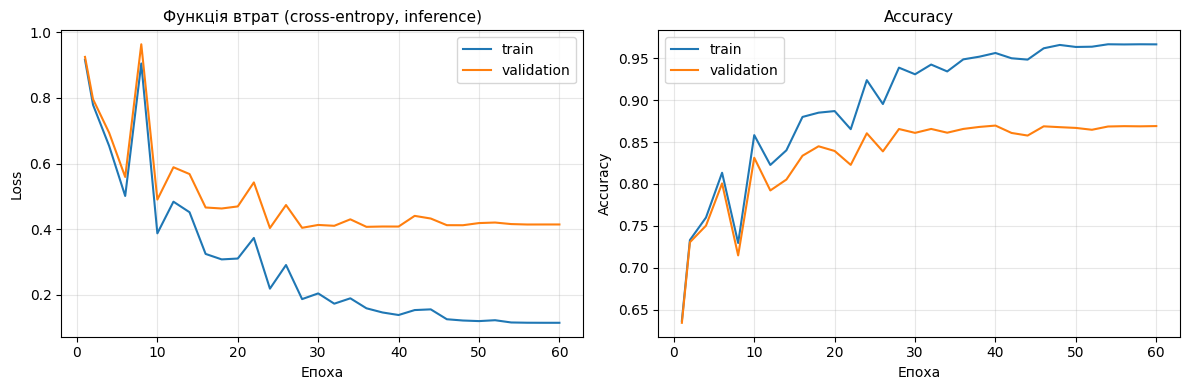

In [7]:
net_base = fresh_net()                      # базова модель: без будь-якої регуляризації
t0 = time.time()
log_base = train(net_base, X_train, y_train, X_val, y_val, PERMS)
print(f'Навчання базової моделі завершено за {time.time() - t0:.0f} с')

h = log_base['hist']
curve = pd.DataFrame({'Епоха': h['epoch'], 'Train loss': np.round(h['train_loss'], 4), 'Val loss': np.round(h['val_loss'], 4),
                      'Train acc': np.round(h['train_acc'], 4), 'Val acc': np.round(h['val_acc'], 4)})
display(curve[curve['Епоха'].isin([1, 10, 20, 30, 40, 50, 60])].set_index('Епоха'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h['epoch'], h['train_loss'], label='train'); axes[0].plot(h['epoch'], h['val_loss'], label='validation')
axes[0].set(title='Функція втрат (cross-entropy, inference)', xlabel='Епоха', ylabel='Loss'); axes[0].legend()
axes[1].plot(h['epoch'], h['train_acc'], label='train'); axes[1].plot(h['epoch'], h['val_acc'], label='validation')
axes[1].set(title='Accuracy', xlabel='Епоха', ylabel='Accuracy'); axes[1].legend()
plt.tight_layout()
plt.show()

Після 60 епох навчальна accuracy становить 96,66%, валідаційна — 86,91%; відповідні значення cross-entropy — 0,1141 і 0,4141. Навчальна втрата загалом знижується, але має коливання, особливо на початку навчання. Розрив accuracy у 9,75 відсоткового пункта та вища валідаційна втрата свідчать про перенавчання.

### 2.5 Перевірка правильності градієнтів

Градієнти базової мережі без регуляризації перевіряються центральною різницею при ε = 10⁻⁵ на 64 навчальних об’єктах. Для кожного шару обираються 5 ваг і 3 зміщення з модулем аналітичного градієнта понад 10⁻⁶. Параметри, для яких збурення перетинає злам ReLU, пропускаються.

In [8]:
def grad_check(net, X, y, l1=0.0, l2=0.0, p=0.0, n_w=5, n_b=3, eps=1e-5, seed=0):
    """Порівняння аналітичних градієнтів із центральною різницею для випадкових ваг і зміщень усіх шарів.
    Параметри, для яких зсув ±eps змінює знаки передактивацій ReLU (злам у нулі), пропускаються й підраховуються."""
    rng = np.random.default_rng(seed)
    masks = None
    if p > 0:                                       # фіксована маска Dropout для всіх обчислень
        net.rng_dropout = np.random.default_rng(seed + 1)
        net.forward(X, train=True, p=p)
        masks = [m for m in net.masks]

    def run():
        net.forward(X, train=p > 0, p=p, masks=masks)
        return net.cross_entropy(net.logits, y) + net.penalty(l1, l2), [z > 0 for z in net.z_values[:-1]]

    _, base_pattern = run()
    net.forward(X, train=p > 0, p=p, masks=masks)
    gW, gb = net.backward(y, l1=l1, l2=l2)

    rows, skipped = [], 0
    for l in range(net.num_layers):
        for kind, params, grads, k in [('W', net.weights, gW, n_w), ('b', net.biases, gb, n_b)]:
            flat_g = grads[l].ravel()
            cand = rng.permutation(np.flatnonzero(np.abs(flat_g) > 1e-6))    # параметри з ненульовим градієнтом
            accepted = 0
            for pos in cand:
                if accepted == k:
                    break
                arr = params[l]
                idx = np.unravel_index(pos, arr.shape)
                old = arr[idx]
                arr[idx] = old + eps; f_plus, pat_p = run()
                arr[idx] = old - eps; f_minus, pat_m = run()
                arr[idx] = old
                if not all(np.array_equal(a, b) and np.array_equal(a, c)
                           for a, b, c in zip(base_pattern, pat_p, pat_m)):
                    skipped += 1                     # зсув перетнув точку зламу ReLU - чисельний градієнт недійсний
                    continue
                g_num = (f_plus - f_minus) / (2 * eps)
                g_an = flat_g[pos]
                err = abs(g_an - g_num) / max(1e-8, abs(g_an) + abs(g_num))
                rows.append({'шар': l + 1, 'параметр': kind, 'індекс': str(tuple(int(i) for i in idx)),
                             'аналітичний': g_an, 'чисельний': g_num, 'E': err})
                accepted += 1
    return pd.DataFrame(rows), skipped


Xg, yg = X_train[:64], y_train[:64]
df_check, skipped = grad_check(fresh_net(), Xg, yg)

detail = df_check.copy()
for col in ['аналітичний', 'чисельний', 'E']:
    detail[col] = detail[col].map(lambda v: f'{v:.2e}')

display(detail.set_index(['шар', 'параметр']))
print(f'Перевірено параметрів: {len(df_check)}')
print(f'Пропущено через злам ReLU: {skipped}')
print(f'Максимальна відносна похибка: {df_check["E"].max():.2e}')

індекс аналітичний  чисельний         E
шар параметр                                             
1   W          (440, 51)   -2.15e-03  -2.15e-03  4.58e-09
    W         (187, 134)    2.82e-03   2.82e-03  2.98e-09
    W          (25, 119)   -1.05e-05  -1.05e-05  9.44e-07
    W         (425, 139)    5.13e-03   5.13e-03  6.51e-10
    W          (509, 80)    7.19e-04   7.19e-04  7.41e-09
    b             (239,)   -4.86e-04  -4.86e-04  2.36e-08
    b             (188,)    2.43e-02   2.43e-02  4.97e-10
    b             (152,)   -2.32e-03  -2.32e-03  1.79e-09
2   W            (3, 55)    8.48e-03   8.48e-03  5.10e-10
    W          (187, 50)   -1.36e-04  -1.36e-04  6.95e-08
    W         (144, 109)   -2.32e-03  -2.32e-03  4.39e-09
    W          (123, 41)   -5.81e-04  -5.81e-04  9.52e-09
    W         (156, 109)   -4.17e-03  -4.17e-03  2.34e-10
    b             (106,)   -2.25e-02  -2.25e-02  2.03e-10
    b               (8,)    4.91e-02   4.91e-02  2.62e-10
    b              (17,)   -1.23e-02  -1.23e-02  3.85e-10
3   W           (79, 41)   -1.58e-03  -1.58e-03  2.21e-09
    W          (126, 21)   -1.45e-03  -1.45e-03  2.22e-09
    W          (109, 46)    3.08e-03   3.08e-03  2.04e-09
    W            (59, 4)    1.64e-04   1.64e-04  6.23e-08
    W           (17, 50)    5.77e-02   5.77e-02  1.81e-10
    b              (40,)   -3.22e-03  -3.22e-03  2.44e-09
    b              (61,)    1.94e-02   1.94e-02  1.18e-10
    b              (37,)    1.80e-04   1.80e-04  2.97e-08
4   W             (2, 5)    7.35e-03   7.35e-03  7.59e-10
    W            (19, 1)    5.44e-02   5.44e-02  5.27e-11
    W            (29, 8)   -2.94e-02  -2.94e-02  1.57e-11
    W            (21, 8)    1.69e-03   1.69e-03  2.12e-09
    W            (56, 3)    5.05e-04   5.05e-04  1.56e-08
    b               (0,)    4.97e-02   4.97e-02  3.07e-10
    b               (1,)    6.86e-02   6.86e-02  1.71e-10
    b               (5,)    5.35e-02   5.35e-02  2.06e-10

Перевірено параметрів: 32
Пропущено через злам ReLU: 0
Максимальна відносна похибка: 9.44e-07


Для 32 перевірених параметрів максимальна відносна похибка становить приблизно 9,44·10⁻⁷. Аналітичні та чисельні градієнти добре узгоджуються.

### 2.6 Збереження та відновлення ваг

`save_weights` записує через `numpy.savez` усі матриці ваг і зміщення, архітектуру (`layer_sizes`) та конфігурацію у вигляді JSON: тип і seed ініціалізації, активації, функцію втрат, тип даних, а також параметри навчання (η, розмір батча, кількість епох, $\lambda_1$, $\lambda_2$, $p$, межі clipping). `load_weights` відновлює все це в існуючий екземпляр і перевіряє збіг архітектури. Перевірка: навчена базова модель зберігається у файл, створюється новий екземпляр із такою самою архітектурою (але з іншою ініціалізацією), у нього завантажуються ваги, після чого порівнюються виходи на всій validation-вибірці.

In [9]:
def save_weights(self, path):
    """Зберігає ваги, зміщення, архітектуру, параметри ініціалізації та конфігурацію навчання."""
    data = {}
    for i, W in enumerate(self.weights):
        data[f'W_{i}'] = W
    for i, b in enumerate(self.biases):
        data[f'b_{i}'] = b
    data['layer_sizes'] = np.array(self.layer_sizes)
    data['config'] = np.array(json.dumps(self.config))        # init, seed, активації, lr, λ, p, clipping тощо
    np.savez(path, **data)


def load_weights(self, path):
    """Завантажує ваги в існуючий екземпляр; архітектура файла має збігатися з архітектурою мережі."""
    data = np.load(path, allow_pickle=False)
    sizes = data['layer_sizes'].tolist()
    if sizes != self.layer_sizes:
        raise ValueError(f'Архітектура файла {sizes} не збігається з архітектурою мережі {self.layer_sizes}')
    self.weights = [data[f'W_{i}'].copy() for i in range(self.num_layers)]
    self.biases = [data[f'b_{i}'].copy() for i in range(self.num_layers)]
    self.config = json.loads(str(data['config']))
    self.dtype = np.dtype(self.config['dtype'])


MLP.save_weights, MLP.load_weights = save_weights, load_weights

path = MODELS_DIR / 'mlp_baseline.npz'
net_base.save_weights(path)
print(f'Збережено: {path} ({path.stat().st_size / 1024:.0f} КБ); ключі:', sorted(np.load(path).files)[:4], '...')

# Новий екземпляр із такою самою архітектурою, але іншою початковою ініціалізацією
net_new = MLP(LAYER_SIZES, seed=999)

net_new.load_weights(path)
P_orig, P_rest = net_base.forward(X_val), net_new.forward(X_val)
diff = np.abs(P_orig - P_rest).max()
same_cls = np.array_equal(P_orig.argmax(1), P_rest.argmax(1))
print(f'Після завантаження: max|P_orig - P_restored| = {diff:.2e}  (вимога < 1e-7: {"виконано" if diff < 1e-7 else "НЕ виконано"})')
print(f'Передбачені класи збігаються для всіх {len(X_val)} об\'єктів: {same_cls}; '
      f'accuracy оригіналу = {(P_orig.argmax(1) == y_val).mean():.4f}, відновленої = {(P_rest.argmax(1) == y_val).mean():.4f}')

print('Відновлена конфігурація:', {k: net_new.config[k] for k in ['init', 'init_seed', 'dtype', 'lr0', 'batch', 'epochs', 'dropout', 'l1', 'l2']})

Збережено: models\mlp_baseline.npz (1900 КБ); ключі: ['W_0', 'W_1', 'W_2', 'W_3'] ...
Після завантаження: max|P_orig - P_restored| = 0.00e+00  (вимога < 1e-7: виконано)
Передбачені класи збігаються для всіх 10000 об'єктів: True; accuracy оригіналу = 0.8691, відновленої = 0.8691
Відновлена конфігурація: {'init': 'he', 'init_seed': 42, 'dtype': 'float64', 'lr0': 0.1, 'batch': 128, 'epochs': 60, 'dropout': 0.0, 'l1': 0.0, 'l2': 0.0}


Після відновлення максимальна різниця вихідних ймовірностей дорівнює 0, що задовольняє вимогу <10⁻⁷. Передбачені класи збігаються для всіх 10 000 валідаційних об’єктів; accuracy обох моделей становить 0,8691. Відновлено також конфігурацію моделі.

## 3. Блок 2. Дослідження впливу регуляризації

### 3.1 Базовий експеримент

Базовою точкою порівняння слугує модель із блоку 1 (без регуляризації). Нижче визначено функції діагностики, фіксуються фінальна accuracy, loss, кількість мертвих нейронів, розподіл ваг кожного шару й частка майже нульових ваг. Допоміжні функції (`summarize`, `run_experiment`, таблиці) використовуються в усіх наступних експериментах. Кожен експеримент починається з копії спільної ініціалізації та має спільні перестановки мінібатчів.

In [10]:
def hidden_activity(net, X, chunk=5000):
    """Максимальні передактивації прихованих нейронів на всій вибірці."""
    z_max = [np.full(n, -np.inf) for n in net.layer_sizes[1:-1]]
    for s in range(0, len(X), chunk):
        net.forward(X[s:s + chunk], train=False)
        for l in range(len(z_max)):
            z_max[l] = np.maximum(
                z_max[l], net.z_values[l].max(axis=0)
            )
    return z_max


def sci(x):
    m, e = f'{x:.0e}'.split('e')
    return f'{m}e{int(e)}'


RESULTS = {}
_perm_cache = {SEED: PERMS}


def summarize(name, family, label, param_text, net, log, cfg):
    """Фінальні метрики моделі після останньої епохи (не найкращі за епохами)."""
    res = {'name': name, 'family': family, 'label': label, 'param_text': param_text, 'cfg': cfg,
           'hist': log['hist'], 'grad_norms': log['grad_norms'], 'n_clipped': log['n_clipped'], 'steps': log['steps'],
           'weights': [W.copy() for W in net.weights], 'biases': [b.copy() for b in net.biases]}
    res['train_loss'], res['train_acc'] = evaluate(net, X_train, y_train)
    res['val_loss'], res['val_acc'] = evaluate(net, X_val, y_val)            # CE без штрафу

    sizes = net.layer_sizes[1:-1]
    z_max = hidden_activity(net, X_train)
    res['neurons'] = sizes
    res['dead'] = [int((z <= 0).sum()) for z in z_max]
    res['dead_pct'] = 100 * sum(res['dead']) / sum(sizes)

    res['sp'] = [(int((np.abs(W) < SPARSITY_THR).sum()), W.size) for W in net.weights]      # строге |W| < 0.01
    hid = res['sp'][:-1]                                                      # матриці W1..W3 прихованих шарів
    res['sparsity_pct'] = 100 * sum(a for a, _ in hid) / sum(b for _, b in hid)
    res['sparsity_all_pct'] = 100 * sum(a for a, _ in res['sp']) / sum(b for _, b in res['sp'])
    wc = cfg.get('weight_clip')
    if wc is not None:
        res['at_bound'] = [(int((np.abs(W) >= wc - 1e-12).sum()), W.size) for W in net.weights]
    return res


def run_experiment(name, family, label, param_text, init_seed=SEED, store=RESULTS, **cfg):
    if init_seed not in _perm_cache:
        _perm_cache[init_seed] = make_perms(init_seed, EPOCHS, len(X_train))
    net = fresh_net(init_seed)                               # кожен експеримент - з копії спільної ініціалізації
    t0 = time.time()
    log = train(net, X_train, y_train, X_val, y_val, _perm_cache[init_seed], **cfg)
    store[name] = summarize(name, family, label, param_text, net, log, cfg)
    r = store[name]
    print(f'{label:<28s} train acc {r["train_acc"]:.4f} | val acc {r["val_acc"]:.4f} | val loss {r["val_loss"]:.4f} | '
          f'dead {r["dead_pct"]:.2f}% | sparsity {r["sparsity_pct"]:.2f}% | {time.time() - t0:.0f} с')
    return net


def metrics_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]
        row = {'Конфігурація': r['label'], 'Train acc, %': f'{100 * r["train_acc"]:.2f}',
               'Val acc, %': f'{100 * r["val_acc"]:.2f}', 'Val loss (CE)': f'{r["val_loss"]:.4f}'}
        row['Dead, %'] = f'{r["dead_pct"]:.2f}'
        row['Sparsity, %'] = f'{r["sparsity_pct"]:.2f}'
        rows.append(row)
    return pd.DataFrame(rows).set_index('Конфігурація')


def dead_table(names):
    rows = []
    for n in names:
        r = RESULTS[n]
        row = {'Конфігурація': r['label']}
        for l, (d, s) in enumerate(zip(r['dead'], r['neurons']), start=1):
            row[f'Шар {l} ({s})'] = f'{d} ({100 * d / s:.2f}%)'
        row['Разом (448)'] = f'{sum(r["dead"])} ({r["dead_pct"]:.2f}%)'
        rows.append(row)
    return pd.DataFrame(rows).set_index('Конфігурація')

Таблиця 3. Фінальні метрики базової моделі (після останньої, 60-ї епохи)


,"Train acc, %","Val acc, %",Val loss (CE),"Dead, %","Sparsity, %"
Конфігурація,,,,,
Без регуляризації,96.66,86.91,0.4141,0.00,13.86


Таблиця 4. Статистика розподілу ваг (sparsity: частка |W| < 0.01)


mean       σ     min     max sparsity, %
Шар          Стан                                                               
W1 (784×256) після He-ініціалізації  -0.0000  0.0506  -0.249  +0.253       15.67
             після навчання          -0.0001  0.0531  -0.252  +0.257       15.06
W2 (256×128) після He-ініціалізації  +0.0002  0.0880  -0.363  +0.361        9.02
             після навчання          +0.0021  0.0930  -0.396  +0.406        8.56
W3 (128×64)  після He-ініціалізації  +0.0011  0.1235  -0.450  +0.481        6.49
             після навчання          +0.0052  0.1365  -0.451  +0.578        5.65
W4 (64×10)   після He-ініціалізації  +0.0017  0.1772  -0.587  +0.511        4.53
             після навчання          +0.0017  0.2761  -0.818  +0.949        2.81

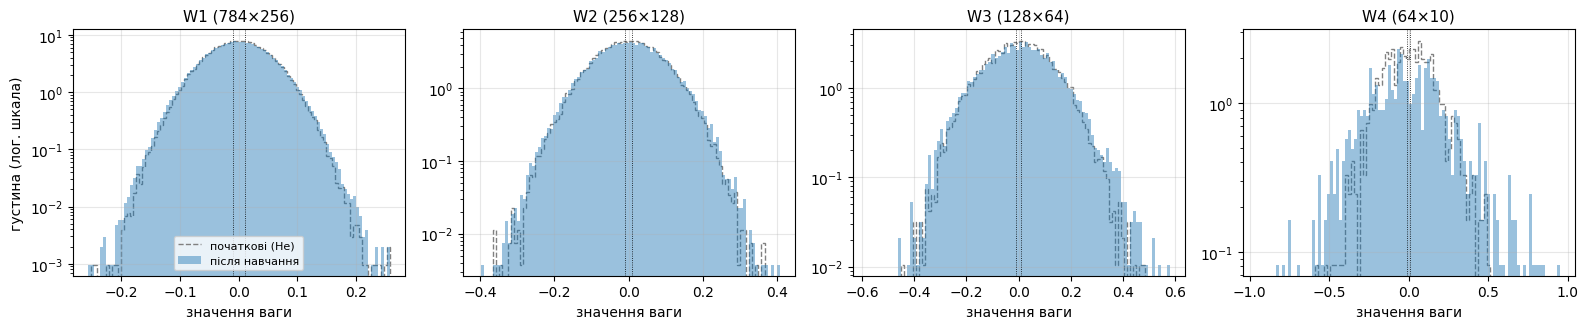

In [11]:
RESULTS['baseline'] = summarize('baseline', 'Без регуляризації', 'Без регуляризації', '—', net_base, log_base, {})

print('Таблиця 3. Фінальні метрики базової моделі (після останньої, 60-ї епохи)')
display(metrics_table(['baseline']))

# Розподіл ваг кожного шару: початковий (He) і після навчання
rows = []
for l in range(4):
    for tag, W in [('після He-ініціалізації', INIT_WEIGHTS[l]), ('після навчання', net_base.weights[l])]:
        a = int((np.abs(W) < SPARSITY_THR).sum())
        rows.append({'Шар': f'W{l + 1} ({W.shape[0]}×{W.shape[1]})', 'Стан': tag, 'mean': f'{W.mean():+.4f}', 'σ': f'{W.std():.4f}',
                     'min': f'{W.min():+.3f}', 'max': f'{W.max():+.3f}', 'sparsity, %': f'{100 * a / W.size:.2f}'})
print('Таблиця 4. Статистика розподілу ваг (sparsity: частка |W| < 0.01)')
display(pd.DataFrame(rows).set_index(['Шар', 'Стан']))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for l, ax in enumerate(axes):
    r = max(np.abs(INIT_WEIGHTS[l]).max(), np.abs(net_base.weights[l]).max())
    edges = np.linspace(-r, r, 101)
    for W, lab, kw in [(INIT_WEIGHTS[l], 'початкові (He)', dict(color='gray', ls='--')),
                       (net_base.weights[l], 'після навчання', dict(color='C0', fill=True, alpha=0.45))]:
        cnt, _ = np.histogram(W, bins=edges, density=True)
        ax.stairs(np.where(cnt > 0, cnt, np.nan), edges, label=lab, **kw)
    ax.axvline(-SPARSITY_THR, color='k', lw=0.6, ls=':'); ax.axvline(SPARSITY_THR, color='k', lw=0.6, ls=':')
    ax.set_yscale('log'); ax.set_title(f'W{l + 1} ({LAYER_SIZES[l]}×{LAYER_SIZES[l + 1]})'); ax.set_xlabel('значення ваги')
axes[0].set_ylabel('густина (лог. шкала)'); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Базова модель має validation accuracy 86,91%, cross-entropy 0,4141 та sparsity прихованих ваг 13,86%. Частина малих ваг існувала вже після He-ініціалізації. Навчання дещо розширило розподіли ваг і зменшило частку майже нульових значень. Показник 13,86% характеризує вже навчену модель без регуляризації та використовується для подальших порівнянь.

### 3.2 Діагностика мертвих нейронів

Для кожного прихованого шару обчислюється $\max_i Z^{(l)}_{ij}$ за всією навчальною підвибіркою (10 000 об'єктів) у режимі inference; нейрон мертвий, якщо цей максимум $\le 0$ (формули (30)–(31)). Діагностика використовує лише `forward(train=False)`, тож випадково вимкнені Dropout-нейрони за мертві не рахуються.

In [12]:
r = RESULTS['baseline']
print('Таблиця 5. Мертві нейрони базової моделі (train-вибірка 10 000 об\'єктів, inference-режим)')
display(dead_table(['baseline']))

Таблиця 5. Мертві нейрони базової моделі (train-вибірка 10 000 об'єктів, inference-режим)


,Шар 1 (256),Шар 2 (128),Шар 3 (64),Разом (448)
Конфігурація,,,,
Без регуляризації,0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)


На всій навчальній підвибірці мертвих нейронів не виявлено: 0 із 256 у першому шарі, 0 зі 128 у другому та 0 із 64 у третьому. Загальна частка становить 0%. Діагностику виконано з вимкненим Dropout.

### 3.3 Дослідження L2-регуляризації

Градієнт ваг доповнюється доданком $\lambda_2 W$ (формула (33)). Досліджено чотири значення $\lambda_2 \in \{10^{-4}, 10^{-3}, 10^{-2}, 3\cdot10^{-2}\}$: від практично нульового впливу до дуже сильного. Інші параметри — як у базовій моделі.

In [13]:
L2_GRID = [1e-4, 1e-3, 1e-2, 3e-2]
for lam in L2_GRID:
    run_experiment(f'l2_{sci(lam)}', 'L2', f'L2 (λ2={sci(lam)})', f'λ2 = {sci(lam)}', l2=lam)
L2_NAMES = [f'l2_{sci(lam)}' for lam in L2_GRID]

L2 (λ2=1e-4)                 train acc 0.9662 | val acc 0.8701 | val loss 0.4085 | dead 0.00% | sparsity 14.17% | 52 с
L2 (λ2=1e-3)                 train acc 0.9519 | val acc 0.8689 | val loss 0.3863 | dead 0.45% | sparsity 17.34% | 52 с
L2 (λ2=1e-2)                 train acc 0.8791 | val acc 0.8508 | val loss 0.4391 | dead 3.57% | sparsity 70.12% | 52 с
L2 (λ2=3e-2)                 train acc 0.8134 | val acc 0.8041 | val loss 0.5925 | dead 9.38% | sparsity 86.54% | 52 с


При λ₂ = 10⁻³ validation loss зменшується з 0,4141 до 0,3863, а accuracy майже не змінюється: 86,89% проти 86,91%. Подальше посилення L2 погіршує навчальну та валідаційну точність. При λ₂ = 0,03 validation accuracy становить 80,41%, sparsity — 86,54%, частка мертвих нейронів — 9,38%. Гістограми в п. 4.2 показують звуження розподілів ваг. Висока sparsity тут означає багато малих за модулем ваг, а не обов’язково точні нулі.

### 3.4 Дослідження L1-регуляризації

До градієнта додається субградієнт $\lambda_1\,\mathrm{sign}(W)$, у нулі рівний нулю. Досліджено $\lambda_1 \in \{10^{-5}, 10^{-4}, 3\cdot10^{-4}, 10^{-3}\}$ — від слабкого до дуже сильного впливу. Оскільки використовується звичайний SGD із субградієнтом (без проксимального кроку), ваги потрапляють не в точні нулі, а коливаються поблизу нуля, тому розрідженість оцінюється за порогом $|W|<0{,}01$.

In [14]:
L1_GRID = [1e-5, 1e-4, 3e-4, 1e-3]
for lam in L1_GRID:
    run_experiment(f'l1_{sci(lam)}', 'L1', f'L1 (λ1={sci(lam)})', f'λ1 = {sci(lam)}', l1=lam)
L1_NAMES = [f'l1_{sci(lam)}' for lam in L1_GRID]

L1 (λ1=1e-5)                 train acc 0.9668 | val acc 0.8691 | val loss 0.4125 | dead 0.00% | sparsity 16.74% | 64 с
L1 (λ1=1e-4)                 train acc 0.9504 | val acc 0.8697 | val loss 0.3840 | dead 0.22% | sparsity 43.02% | 64 с
L1 (λ1=3e-4)                 train acc 0.9033 | val acc 0.8635 | val loss 0.3917 | dead 1.34% | sparsity 79.77% | 64 с
L1 (λ1=1e-3)                 train acc 0.8488 | val acc 0.8335 | val loss 0.4799 | dead 22.99% | sparsity 98.37% | 64 с


При λ₁ = 10⁻⁴ validation loss зменшується до 0,3840, accuracy становить 86,97%, sparsity — 43,02%, мертвий нейрон лише один. При λ₁ = 10⁻³ sparsity зростає до 98,37%, але accuracy падає до 83,35%, а кількість мертвих нейронів досягає 103 із 448. Отже, помірна L1-регуляризація дає вдалий компроміс, тоді як сильна призводить до недонавчання. На гістограмах зростає концентрація ваг поблизу нуля, водночас частина великих ваг зберігається.

### 3.5 Дослідження Dropout

Inverted dropout застосовується до виходів усіх трьох прихованих шарів: $\tilde A = A\odot M/(1-p)$, $M_i\sim\mathrm{Bernoulli}(1-p)$. Виконано всі задані значення $p \in \{0{,}1;\,0{,}3;\,0{,}5\}$ і додатково $p = 0{,}2$ — для порівняння з комбінацією L2 + Dropout у п. 3.8. Оцінювання, діагностика мертвих нейронів і sparsity виконуються в режимі inference.

In [15]:
DO_GRID = [0.1, 0.2, 0.3, 0.5]          # 0.1, 0.3, 0.5 - за вимогами; 0.2 - для порівняння з комбінацією у п. 3.8
for p in DO_GRID:
    extra = '' if p != 0.2 else ' (додатково, для п. 3.8)'
    run_experiment(f'do_{p}', 'Dropout', f'Dropout p={p}', f'p = {p}{extra}', p=p)
DO_NAMES = [f'do_{p}' for p in DO_GRID]

Dropout p=0.1                train acc 0.9486 | val acc 0.8756 | val loss 0.3921 | dead 0.00% | sparsity 13.81% | 45 с
Dropout p=0.2                train acc 0.9353 | val acc 0.8727 | val loss 0.3962 | dead 0.00% | sparsity 13.91% | 45 с
Dropout p=0.3                train acc 0.9231 | val acc 0.8683 | val loss 0.4007 | dead 0.00% | sparsity 13.89% | 45 с
Dropout p=0.5                train acc 0.8917 | val acc 0.8522 | val loss 0.4326 | dead 0.00% | sparsity 14.01% | 45 с


Найвища validation accuracy серед перевірених значень Dropout отримана при p = 0,1 — 87,56%. При p = 0,5 вона знижується до 85,22%, а навчальна accuracy — до 89,17%, що вказує на недонавчання за обраної тривалості навчання. Тому збільшення ймовірності вимкнення нейронів не гарантує покращення якості. Мертвих нейронів не виявлено в жодному варіанті; sparsity залишається близькою до базової — 13,8–14,0%. Розподіли ваг наведено в п. 4.2.

### 3.6 Дослідження weight clipping

Після кожного оновлення всі матриці ваг обмежуються діапазоном [−1; 1]. Зміщення не обмежуються. Порівнюються фінальні метрики, розподіли ваг, sparsity, мертві нейрони та кількість ваг на межах діапазону.

In [16]:
WC_GRID = [1.0]
for c in WC_GRID:
    extra = ' (за методичкою)' if c == 1.0 else ' (додатково)'
    run_experiment(f'wc_{c}', 'Weight clipping', f'Weight clip ±{c:g}', f'c = {c:g}{extra}', weight_clip=c)
WC_NAMES = [f'wc_{c}' for c in WC_GRID]

rows = []
for n in WC_NAMES:
    r = RESULTS[n]
    row = {'Конфігурація': r['label']}
    for l, (a, b) in enumerate(r['at_bound'], start=1):
        row[f'W{l}: ваг на межі'] = f'{a} ({100 * a / b:.2f}%)'
    row['Усього на межі'] = f'{sum(a for a, _ in r["at_bound"])} ({100 * sum(a for a, _ in r["at_bound"]) / sum(b for _, b in r["at_bound"]):.3f}%)'
    rows.append(row)
print('Таблиця 17. Кількість ваг на межах ±1 після навчання')
display(pd.DataFrame(rows).set_index('Конфігурація'))
print('max|W| за шарами (W1..W4):')
for n in ['baseline'] + WC_NAMES:
    print(f'  {RESULTS[n]["label"]:<20s}', [round(float(np.abs(W).max()), 3) for W in RESULTS[n]['weights']])

Weight clip ±1               train acc 0.9666 | val acc 0.8691 | val loss 0.4141 | dead 0.00% | sparsity 13.86% | 43 с
Таблиця 17. Кількість ваг на межах ±1 після навчання


,W1: ваг на межі,W2: ваг на межі,W3: ваг на межі,W4: ваг на межі,Усього на межі
Конфігурація,,,,,
Weight clip ±1,0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%),0 (0.000%)


max|W| за шарами (W1..W4):
  Без регуляризації    [0.257, 0.406, 0.578, 0.949]
  Weight clip ±1       [0.257, 0.406, 0.578, 0.949]


Після навчання ваг на межах ±1 немає; максимальний модуль ваги становить 0,949. Наведені метрики збігаються з baseline: validation accuracy 86,91%, loss 0,4141, sparsity 13,86%, мертвих нейронів немає. Для цієї конфігурації помітного ефекту обмеження не виявлено. Загалом weight clipping звужує допустиму область параметрів і може заважати навчанню, якщо потрібні значення ваг виходять за встановлені межі.

### 3.7 Дослідження gradient clipping

Градієнт обмежується за глобальною $L_2$-нормою, обчисленою за всіма градієнтами ваг і зміщень: $g \leftarrow g\cdot\min(1, c/\lVert g\rVert_2)$ перед оновленням. Щоб порогові значення були обґрунтованими, спершу розглянуто розподіл норм градієнта в базовому навчанні (воно відбувалося без clipping).

In [17]:
gn = RESULTS['baseline']['grad_norms']          # норми градієнта базового навчання (до будь-якого clipping)
GC_GRID = [5.0, 2.0, 1.0, 0.5]
pct_rows = [{'Показник': 'медіана', 'Значення': np.median(gn)}, {'Показник': '90-й перцентиль', 'Значення': np.percentile(gn, 90)},
            {'Показник': '99-й перцентиль', 'Значення': np.percentile(gn, 99)}, {'Показник': 'максимум', 'Значення': gn.max()}]
display(pd.DataFrame(pct_rows).set_index('Показник').round(3))
print('Частка кроків базового навчання з нормою, більшою за поріг c (очікувана частка спрацювань clipping):')
for c in GC_GRID:
    print(f'  c = {c:<4g}: {100 * (gn > c).mean():.1f}%')

,Значення
Показник,
медіана,1.245
90-й перцентиль,1.874
99-й перцентиль,3.192
максимум,7.449


Частка кроків базового навчання з нормою, більшою за поріг c (очікувана частка спрацювань clipping):
  c = 5   : 0.1%
  c = 2   : 7.3%
  c = 1   : 79.6%
  c = 0.5 : 100.0%


У базовому навчанні медіана норми градієнта 1,25, 90-й перцентиль 1,87, 99-й — 3,19, максимум 7,45. Тому обрано чотири пороги різної сили: $c = 5$ (спрацьовує лише на рідкісних сплесках — у 0,1 % кроків базового навчання), $c = 2$ (близько 7 % кроків, спрацьовує на верхніх 10 % норм), $c = 1$ (майже завжди, ≈80 % кроків) і $c = 0{,}5$ (на кожному кроці).

Grad. clip c=5               train acc 0.9680 | val acc 0.8699 | val loss 0.4145 | dead 0.22% | sparsity 13.84% | 42 с
Grad. clip c=2               train acc 0.9682 | val acc 0.8701 | val loss 0.4168 | dead 0.00% | sparsity 13.84% | 42 с
Grad. clip c=1               train acc 0.9408 | val acc 0.8651 | val loss 0.4099 | dead 0.45% | sparsity 14.13% | 42 с
Grad. clip c=0.5             train acc 0.9037 | val acc 0.8573 | val loss 0.4192 | dead 0.67% | sparsity 14.28% | 42 с

Таблиця 20. Метрики gradient clipping та показники стабільності функції втрат


,"Кроків із clipping, %","Train acc, %","Val acc, %",Val loss (CE),"Dead, %","Sparsity, %",Зростань train loss між оцінками,"Макс. стрибок train loss, %"
Конфігурація,,,,,,,,
Без регуляризації,0.0,96.66,86.91,0.4141,0.00,13.86,10,80.7
Grad. clip c=5,0.1,96.80,86.99,0.4145,0.22,13.84,10,55.3
Grad. clip c=2,9.1,96.82,87.01,0.4168,0.00,13.84,5,46.2
Grad. clip c=1,95.7,94.08,86.51,0.4099,0.45,14.13,8,27.9
Grad. clip c=0.5,100.0,90.37,85.73,0.4192,0.67,14.28,6,13.7


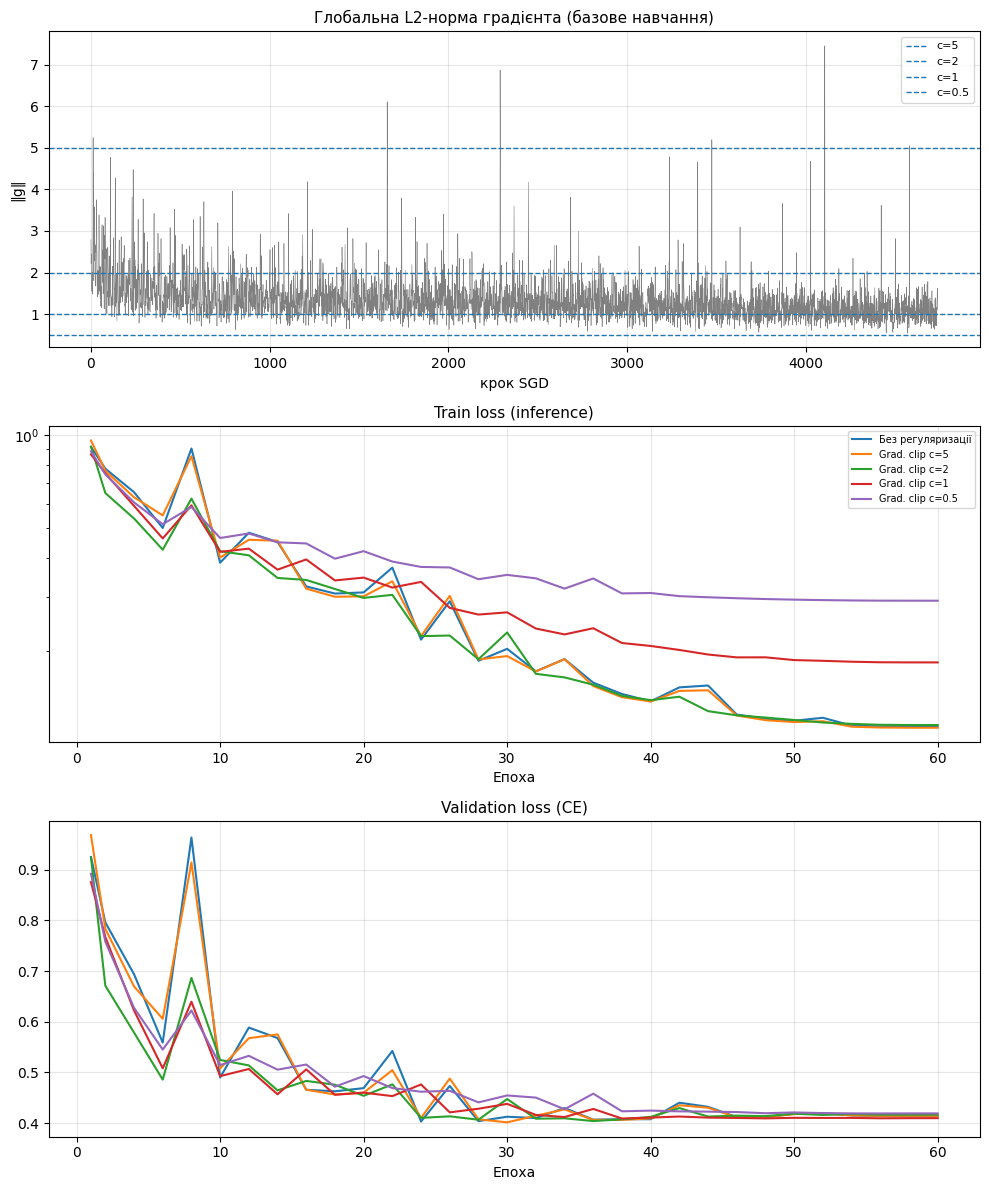

In [28]:
for c in GC_GRID:
    run_experiment(f'gc_{c:g}', 'Gradient clipping', f'Grad. clip c={c:g}', f'c = {c:g}', grad_clip=c)
GC_NAMES = [f'gc_{c:g}' for c in GC_GRID]


def stability(r):
    tl = np.array(r['hist']['train_loss'])
    up = np.diff(tl)
    return int((up > 0).sum()), float(np.max(np.diff(tl) / tl[:-1]) * 100)


rows = []
for n in ['baseline'] + GC_NAMES:
    r = RESULTS[n]
    n_up, max_up = stability(r)
    rows.append({'Конфігурація': r['label'], 'Кроків із clipping, %': f'{100 * r["n_clipped"] / r["steps"]:.1f}',
                 'Train acc, %': f'{100 * r["train_acc"]:.2f}', 'Val acc, %': f'{100 * r["val_acc"]:.2f}', 'Val loss (CE)': f'{r["val_loss"]:.4f}',
                 'Dead, %': f'{r["dead_pct"]:.2f}', 'Sparsity, %': f'{r["sparsity_pct"]:.2f}',
                 'Зростань train loss між оцінками': n_up, 'Макс. стрибок train loss, %': f'{max_up:.1f}'})
print('\nТаблиця 20. Метрики gradient clipping та показники стабільності функції втрат')
display(pd.DataFrame(rows).set_index('Конфігурація'))

fig, axes = plt.subplots(3, 1, figsize=(10, 12)) 
axes[0].plot(gn, lw=0.4, color='gray')
for c in GC_GRID:
    axes[0].axhline(c, ls='--', lw=1, label=f'c={c:g}')
axes[0].set(title='Глобальна L2-норма градієнта (базове навчання)', xlabel='крок SGD', ylabel='‖g‖')
axes[0].legend(fontsize=8)
for n in ['baseline'] + GC_NAMES:
    r = RESULTS[n]
    axes[1].plot(r['hist']['epoch'], r['hist']['train_loss'], label=r['label'])
    axes[2].plot(r['hist']['epoch'], r['hist']['val_loss'], label=r['label'])
axes[1].set(title='Train loss (inference)', xlabel='Епоха')
axes[2].set(title='Validation loss (CE)', xlabel='Епоха')
axes[1].set_yscale('log')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

При c = 5 та c = 2 validation accuracy близька до базової: 86,99% і 87,01%. При c = 0,5 clipping застосовується на кожному кроці: максимальний стрибок train loss зменшується з 80,7% до 13,7%, але validation accuracy падає до 85,73%. Отже, сильне обмеження згладжує коливання ціною повільнішого навчання. Sparsity залишається в межах 13,84–14,28%, а кількість мертвих нейронів — від 0 до 3. Гістограми близькі до baseline: gradient clipping обмежує градієнти, а не діапазон самих ваг.

### 3.8 Комбінована регуляризація

Комбінація L2 + Dropout $p = 0{,}2$ порівнюється з окремими L2 (той самий $\lambda_2$) та Dropout $p=0{,}2$ (п. 3.5). Значення $\lambda_2$ вибрано за найменшим validation loss (CE без штрафу) серед L2-експериментів п. 3.3 — воно відображає покращення узагальнення без впливу самого штрафу.

In [19]:
best_l2 = min(L2_NAMES, key=lambda n: RESULTS[n]['val_loss'])      # λ2 з найменшою val cross-entropy серед L2-сітки
LAM2_STAR = RESULTS[best_l2]['cfg']['l2']
print(f'Обраний λ2 для комбінації: {sci(LAM2_STAR)} (найменший Val loss серед L2-експериментів)')

run_experiment('combo', 'L2 + Dropout', f'L2 (λ2={sci(LAM2_STAR)}) + Dropout 0.2', f'λ2 = {sci(LAM2_STAR)}, p = 0.2', l2=LAM2_STAR, p=0.2)
COMBO_NAMES = ['baseline', best_l2, 'do_0.2', 'combo']

print('\nТаблиця 23. Комбінована регуляризація та відповідні окремі методи (однакові λ2 і p = 0.2)')
display(metrics_table(COMBO_NAMES))

b = RESULTS
print(f'Δ val acc комбінації відносно L2: {100 * (b["combo"]["val_acc"] - b[best_l2]["val_acc"]):+.2f} п.п.; '
      f'відносно Dropout 0.2: {100 * (b["combo"]["val_acc"] - b["do_0.2"]["val_acc"]):+.2f} п.п.; '
      f'відносно базової: {100 * (b["combo"]["val_acc"] - b["baseline"]["val_acc"]):+.2f} п.п.')

Обраний λ2 для комбінації: 1e-3 (найменший Val loss серед L2-експериментів)
L2 (λ2=1e-3) + Dropout 0.2   train acc 0.9312 | val acc 0.8727 | val loss 0.3845 | dead 0.00% | sparsity 17.30% | 55 с

Таблиця 23. Комбінована регуляризація та відповідні окремі методи (однакові λ2 і p = 0.2)


,"Train acc, %","Val acc, %",Val loss (CE),"Dead, %","Sparsity, %"
Конфігурація,,,,,
Без регуляризації,96.66,86.91,0.4141,0.00,13.86
L2 (λ2=1e-3),95.19,86.89,0.3863,0.45,17.34
Dropout p=0.2,93.53,87.27,0.3962,0.00,13.91
L2 (λ2=1e-3) + Dropout 0.2,93.12,87.27,0.3845,0.00,17.30


Δ val acc комбінації відносно L2: +0.38 п.п.; відносно Dropout 0.2: +0.00 п.п.; відносно базової: +0.36 п.п.


Комбінація L2 з λ₂ = 10⁻³ та Dropout 0.2 дає accuracy 87,27% — як окремий Dropout і на 0,38 відсоткового пункта вище за окремий L2. Її loss становить 0,3845 проти 0,3863 для L2 та 0,3962 для Dropout. Мертвих нейронів немає, тоді як окремий L2 має два. Sparsity комбінації — 17,30%, близька до L2 (17,34%) і вища за Dropout (13,91%). Покращення є за loss, але додаткового виграшу accuracy порівняно з Dropout немає; ознак різкого погіршення через надмірне обмеження також не виявлено.

## 4. Аналіз та порівняння результатів

### 4.1 Порівняльна таблиця

Нижче зібрано всі дослідженi конфігурації з параметрами $\lambda_1$, $\lambda_2$, $p$ та порогами clipping. Усі значення — фінальні (після 60-ї епохи). Dead neurons — частка від 448 прихованих нейронів, Sparsity — частка ваг $W^{(1)}$–$W^{(3)}$ з $|W|<0{,}01$; Val. loss — cross-entropy без штрафу. Рядок Dropout 0,2 і комбінація додані для п. 3.8.

In [20]:
ORDER = (['baseline'] + L1_NAMES + L2_NAMES + DO_NAMES + WC_NAMES + GC_NAMES + ['combo'])
rows = []
for n in ORDER:
    r = RESULTS[n]
    rows.append({'Метод': r['family'], 'Параметри': r['param_text'], 'Dead neurons, %': f'{r["dead_pct"]:.2f}', 'Sparsity, %': f'{r["sparsity_pct"]:.2f}', 
                 'Val. accuracy, %': f'{100 * r["val_acc"]:.2f}', 'Val. loss': f'{r["val_loss"]:.4f}', 'Train accuracy, %': f'{100 * r["train_acc"]:.2f}'})
summary_df = pd.DataFrame(rows)
print(f'Таблиця 26. Порівняння всіх {len(ORDER)} досліджених конфігурацій (фінальні значення після епохи {EPOCHS})')
display(summary_df.set_index(['Метод', 'Параметри']))

print('Таблиця 27. Мертві нейрони за прихованими шарами для всіх конфігурацій')
display(dead_table(ORDER))
print('Таблиця 28. Sparsity (%) за матрицями ваг: W1-W3 - приховані шари, W4 - вихідний шар')
sp_rows = []
for n in ORDER:
    r = RESULTS[n]
    row = {'Конфігурація': r['label']}
    for l, (a, b) in enumerate(r['sp'], start=1):
        row[f'W{l}'] = f'{100 * a / b:.2f}'
    row['W1-W3 (у табл. 26)'] = f'{r["sparsity_pct"]:.2f}'
    row['W1-W4'] = f'{r["sparsity_all_pct"]:.2f}'
    sp_rows.append(row)
display(pd.DataFrame(sp_rows).set_index('Конфігурація'))

Таблиця 26. Порівняння всіх 19 досліджених конфігурацій (фінальні значення після епохи 60)


Dead neurons, % Sparsity, % Val. accuracy, % Val. loss Train accuracy, %
Метод             Параметри                                                                                               
Без регуляризації —                                          0.00       13.86            86.91    0.4141             96.66
L1                λ1 = 1e-5                                  0.00       16.74            86.91    0.4125             96.68
                  λ1 = 1e-4                                  0.22       43.02            86.97    0.3840             95.04
                  λ1 = 3e-4                                  1.34       79.77            86.35    0.3917             90.33
                  λ1 = 1e-3                                 22.99       98.37            83.35    0.4799             84.88
L2                λ2 = 1e-4                                  0.00       14.17            87.01    0.4085             96.62
                  λ2 = 1e-3                                  0.45       17.34            86.89    0.3863             95.19
                  λ2 = 1e-2                                  3.57       70.12            85.08    0.4391             87.91
                  λ2 = 3e-2                                  9.38       86.54            80.41    0.5925             81.34
Dropout           p = 0.1                                    0.00       13.81            87.56    0.3921             94.86
                  p = 0.2 (додатково, для п. 3.8)            0.00       13.91            87.27    0.3962             93.53
                  p = 0.3                                    0.00       13.89            86.83    0.4007             92.31
                  p = 0.5                                    0.00       14.01            85.22    0.4326             89.17
Weight clipping   c = 1 (за методичкою)                      0.00       13.86            86.91    0.4141             96.66
Gradient clipping c = 5                                      0.22       13.84            86.99    0.4145             96.80
                  c = 2                                      0.00       13.84            87.01    0.4168             96.82
                  c = 1                                      0.45       14.13            86.51    0.4099             94.08
                  c = 0.5                                    0.67       14.28            85.73    0.4192             90.37
L2 + Dropout      λ2 = 1e-3, p = 0.2                         0.00       17.30            87.27    0.3845             93.12

Таблиця 27. Мертві нейрони за прихованими шарами для всіх конфігурацій


,Шар 1 (256),Шар 2 (128),Шар 3 (64),Разом (448)
Конфігурація,,,,
Без регуляризації,0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
L1 (λ1=1e-5),0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
L1 (λ1=1e-4),0 (0.00%),0 (0.00%),1 (1.56%),1 (0.22%)
L1 (λ1=3e-4),0 (0.00%),1 (0.78%),5 (7.81%),6 (1.34%)
L1 (λ1=1e-3),74 (28.91%),20 (15.62%),9 (14.06%),103 (22.99%)
L2 (λ2=1e-4),0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
L2 (λ2=1e-3),0 (0.00%),0 (0.00%),2 (3.12%),2 (0.45%)
L2 (λ2=1e-2),0 (0.00%),7 (5.47%),9 (14.06%),16 (3.57%)
L2 (λ2=3e-2),17 (6.64%),14 (10.94%),11 (17.19%),42 (9.38%)


Таблиця 28. Sparsity (%) за матрицями ваг: W1-W3 - приховані шари, W4 - вихідний шар


,W1,W2,W3,W4,W1-W3 (у табл. 26),W1-W4
Конфігурація,,,,,,
Без регуляризації,15.06,8.56,5.65,2.81,13.86,13.83
L1 (λ1=1e-5),18.20,10.25,7.08,2.50,16.74,16.70
L1 (λ1=1e-4),46.61,27.12,18.80,5.62,43.02,42.92
L1 (λ1=3e-4),84.51,59.89,43.30,19.53,79.77,79.61
L1 (λ1=1e-3),98.96,97.41,87.81,54.69,98.37,98.26
L2 (λ2=1e-4),15.35,8.92,6.15,2.97,14.17,14.14
L2 (λ2=1e-3),18.82,10.81,7.40,3.59,17.34,17.31
L2 (λ2=1e-2),75.04,48.93,34.27,14.38,70.12,69.97
L2 (λ2=3e-2),90.00,72.19,59.14,25.31,86.54,86.38


Найвища validation accuracy — у Dropout 0,1 (87,56 %); найменший validation loss — у L1 $10^{-4}$ (0,3840), комбінації L2 + Dropout 0,2 (0,3845) і L2 $10^{-3}$ (0,3863), проти 0,4141 у базової. Ненульові частки мертвих нейронів помітні лише при сильній регуляризації: L1 $10^{-3}$ — 22,99 %, L2 $3\cdot10^{-2}$ — 9,38 %, L2 $10^{-2}$ — 3,57 %; в усіх інших конфігураціях вони не перевищують 1,34 % (≤ 6 нейронів), а в Dropout усіх значень $p$ дорівнюють нулю. Найбільша sparsity — у L1 $10^{-3}$ (98,37 %), L2 $3\cdot10^{-2}$ (86,54 %), L1 $3\cdot10^{-4}$ (79,77 %) і L2 $10^{-2}$ (70,12 %); у Dropout, weight clipping і gradient clipping sparsity лишається майже такою ж, як у базової (13,8–14,3 %). Таблиця 28 показує, що sparsity за $W^{(4)}$ (вихідний шар) нижча, ніж у прихованих шарах, а в показник 4.1 вона не входить, і додавання $W^{(4)}$ змінює цей показник не більше ніж на 0,2 п.п. в усіх конфігураціях.

Відмінності наведено для одного запуску кожної конфігурації. Статистичну значущість різниць між моделями не перевірено.

### 4.2 Розподіл ваг

Для кожного методу побудовано гістограми ваг $W^{(1)}$, $W^{(2)}$ і $W^{(3)}$ прихованих шарів: сірий пунктир — початковий розподіл після He-ініціалізації, чорна лінія — після навчання без регуляризації, заливка — модель із відповідною регуляризацією. Вертикальні червоні пунктири позначають $\pm0{,}01$ (поріг sparsity), зелені лінії у weight clipping — межі $\pm c$. Вісь $y$ — логарифмічна (щоб бачити хвости й піки біля нуля); для кожного стовпця спільний діапазон по $x$.

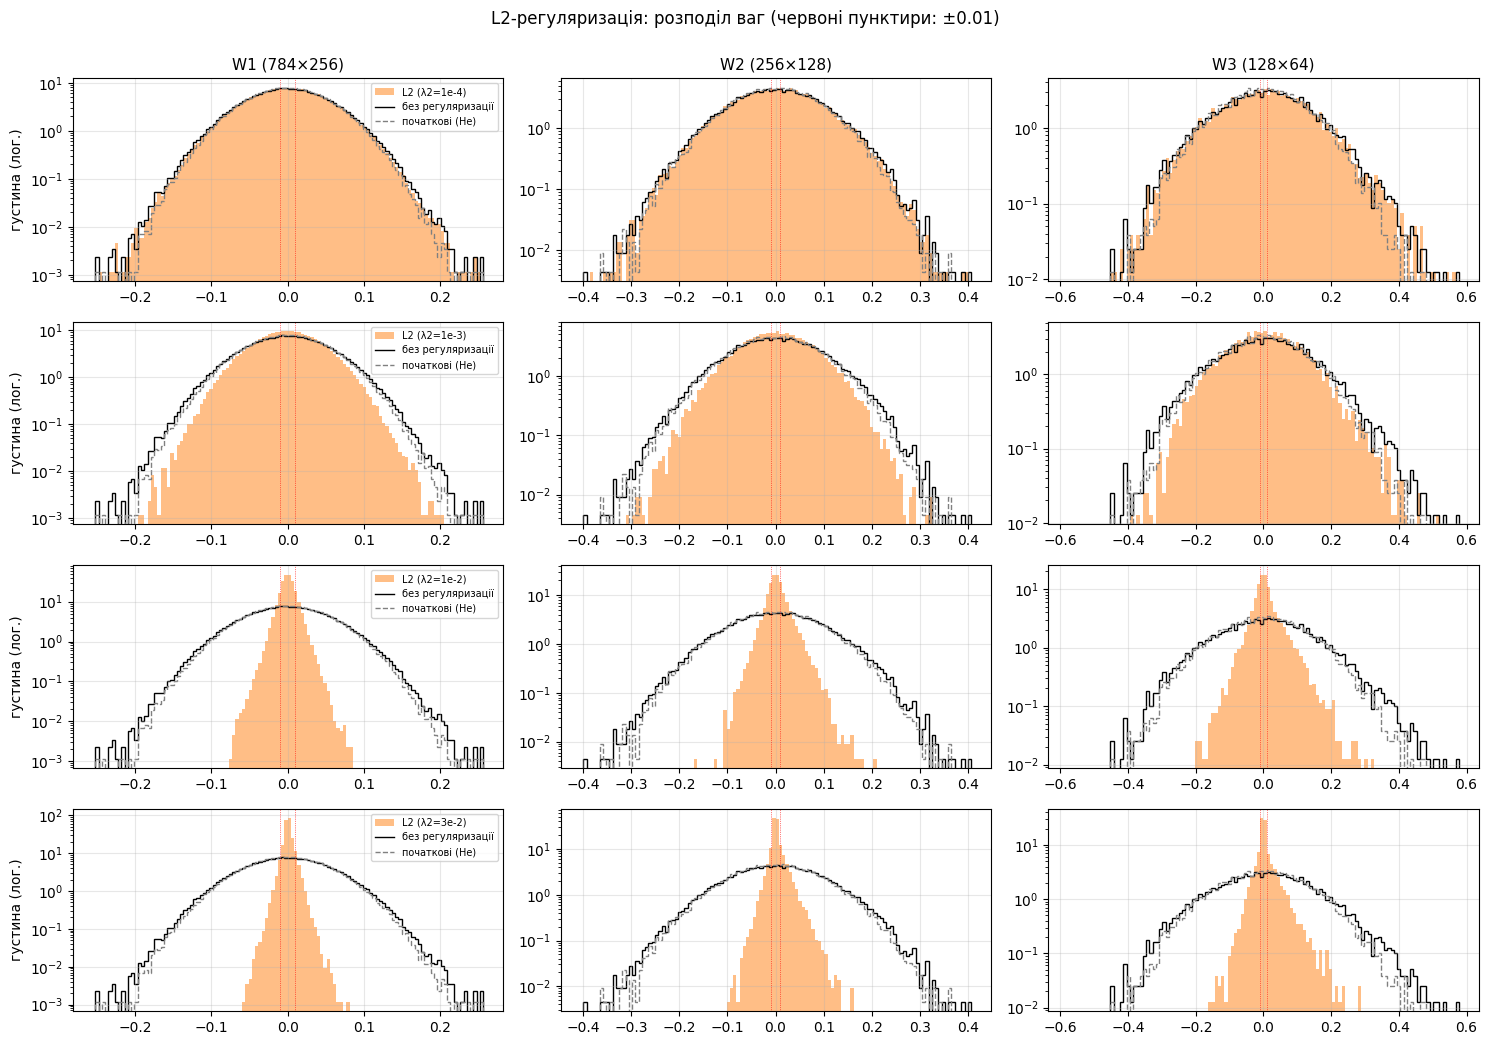

In [21]:
def plot_weight_hists(names, title, bound=None):
    """Гістограми ваг W1-W3 (приховані шари): початкові (He), базова модель і кожна конфігурація набору."""
    n_rows = len(names)
    fig, axes = plt.subplots(n_rows, 3, figsize=(15, 2.6 * n_rows), squeeze=False)
    for l in range(3):
        arrays = [INIT_WEIGHTS[l].ravel(), RESULTS['baseline']['weights'][l].ravel()] + [RESULTS[n]['weights'][l].ravel() for n in names]
        r = max(np.abs(a).max() for a in arrays)
        edges = np.linspace(-r, r, 121)
        cnt_init, _ = np.histogram(arrays[0], bins=edges, density=True)
        cnt_base, _ = np.histogram(arrays[1], bins=edges, density=True)
        for i, n in enumerate(names):
            ax = axes[i, l]
            cnt, _ = np.histogram(RESULTS[n]['weights'][l].ravel(), bins=edges, density=True)
            ax.stairs(np.where(cnt > 0, cnt, np.nan), edges, fill=True, alpha=0.5, color='C1', label=RESULTS[n]['label'])
            ax.stairs(np.where(cnt_base > 0, cnt_base, np.nan), edges, color='k', lw=1, label='без регуляризації')
            ax.stairs(np.where(cnt_init > 0, cnt_init, np.nan), edges, color='gray', lw=1, ls='--', label='початкові (He)')
            ax.axvline(-SPARSITY_THR, color='r', lw=0.5, ls=':'); ax.axvline(SPARSITY_THR, color='r', lw=0.5, ls=':')
            if bound is not None and RESULTS[n]['cfg'].get('weight_clip'):
                c = RESULTS[n]['cfg']['weight_clip']
                ax.axvline(-c, color='g', lw=0.8); ax.axvline(c, color='g', lw=0.8)
            ax.set_yscale('log')
            if i == 0:
                ax.set_title(f'W{l + 1} ({LAYER_SIZES[l]}×{LAYER_SIZES[l + 1]})')
            if l == 0:
                ax.set_ylabel('густина (лог.)')
                ax.legend(fontsize=7, loc='upper right')
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()


plot_weight_hists(L2_NAMES, 'L2-регуляризація: розподіл ваг (червоні пунктири: ±0.01)')

**L2.** Розподіл звужується зі зростанням $\lambda_2$ ($\sigma(W^{(1)})$: 0,0519; 0,0425; 0,0101; 0,0061; максимум $|W^{(1)}|$ — 0,084 при $\lambda_2 = 10^{-2}$ проти 0,257 у базової). При $10^{-4}$ гістограма майже не відрізняється від базової. Це зсув усього розподілу до нуля, без окремого піка в нулі: хвости зникають, а «горб» стискається. Тому зростання sparsity до 70–87 % відображає малий масштаб ваг, а не точні нулі.

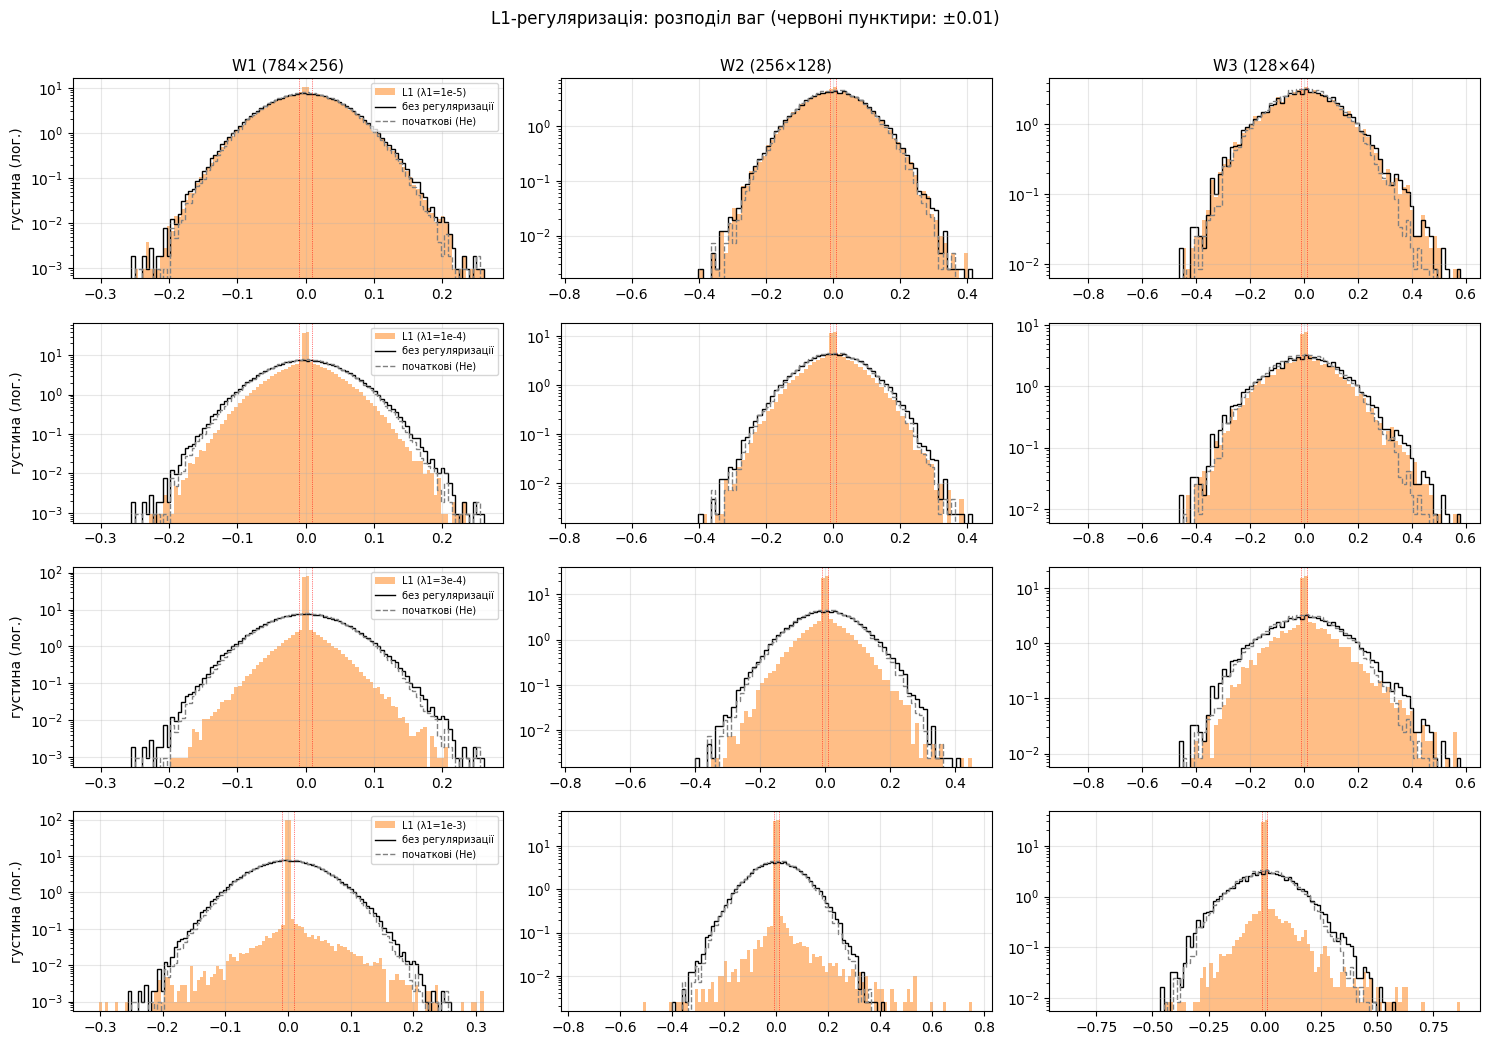

In [22]:
plot_weight_hists(L1_NAMES, 'L1-регуляризація: розподіл ваг (червоні пунктири: ±0.01)')

**L1.** З ростом $\lambda_1$ з'являється гострий пік у нулі ($|W|<0{,}01$), а хвости при цьому не зникають: при $\lambda_1 = 10^{-3}$ більшість ваг поблизу нуля, а решта розсіяна в широкому діапазоні, у $W^{(2)}$ і $W^{(3)}$ — навіть ширшому, ніж у базової моделі (максимум $|W^{(2)}|$ 0,753 проти 0,406, $|W^{(3)}|$ 0,872 проти 0,578). Тобто L1 розділяє ваги на майже нульові та кілька великих, тоді як L2 стискає всі ваги разом. Це і є відмінність «розрідженості» L1 від «малих ваг» L2.

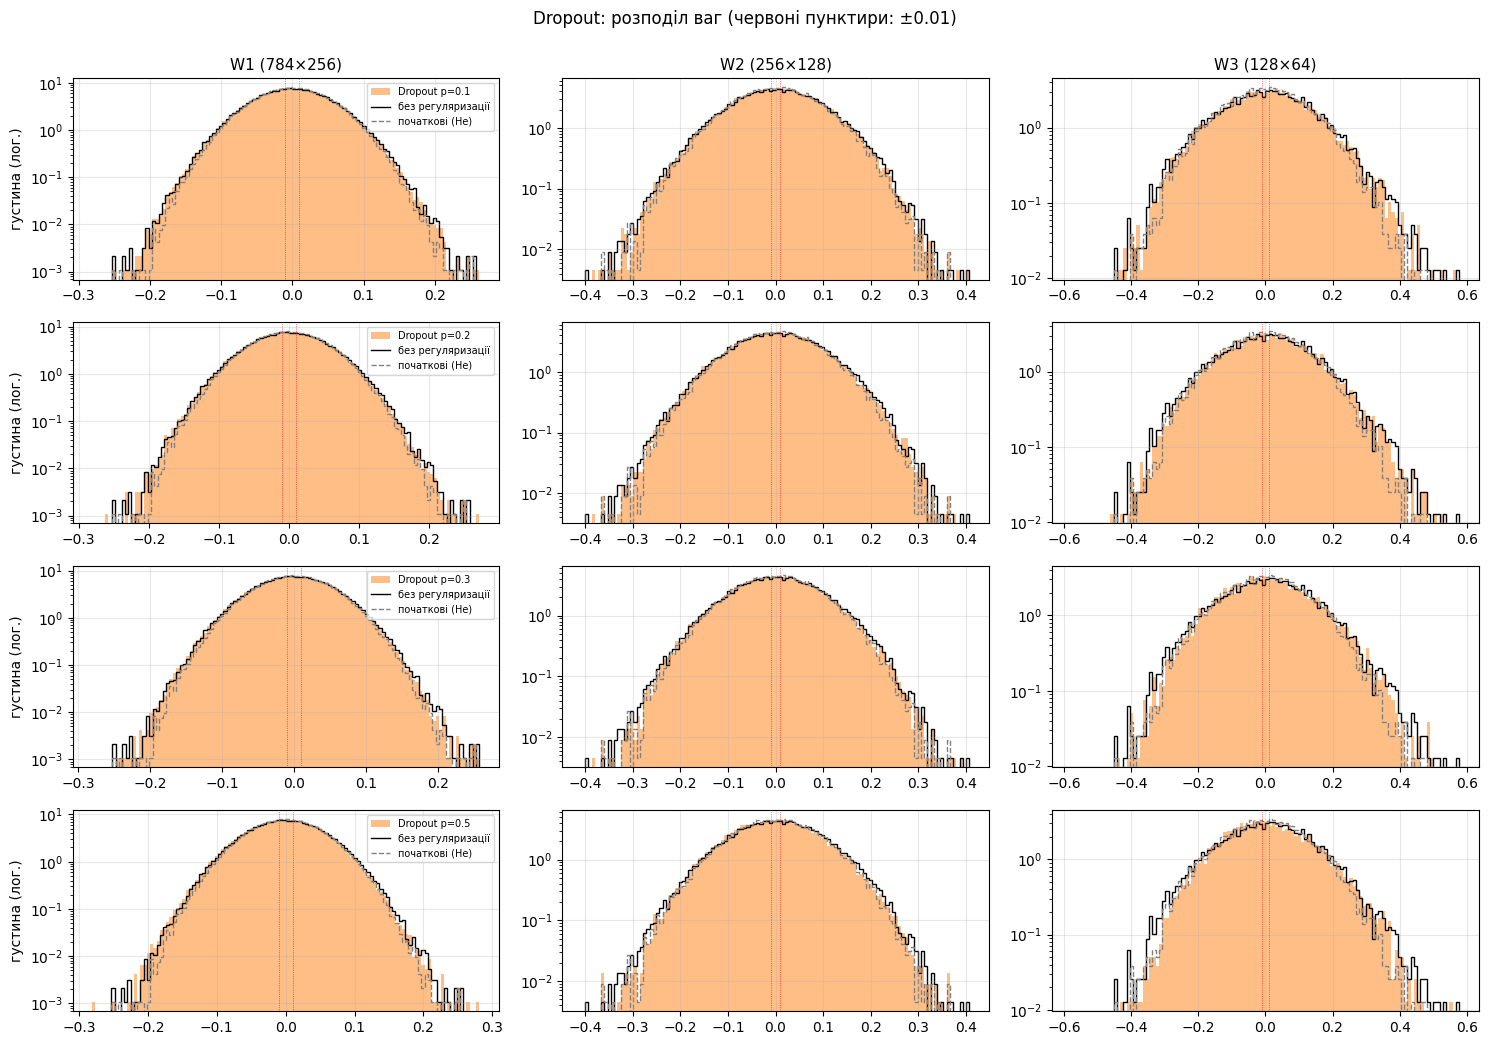

In [23]:
plot_weight_hists(DO_NAMES, 'Dropout: розподіл ваг (червоні пунктири: ±0.01)')

**Dropout.** Розподіли ваг у всіх чотирьох варіантах практично збігаються з базовим ($\sigma(W^{(1)})$ 0,0527–0,0529 проти 0,0531, sparsity 13,8–14,0 %): Dropout не штрафує ваги, а змінює активації, і його вплив видно за train/validation accuracy (п. 3.5), а не за гістограмами ваг.

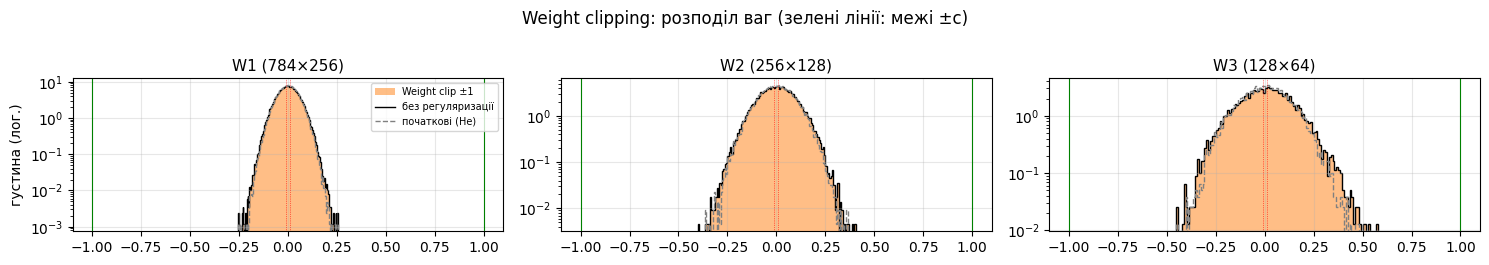

In [24]:
plot_weight_hists(WC_NAMES, 'Weight clipping: розподіл ваг (зелені лінії: межі ±c)', bound=True)

**Weight clipping.** При c = 1 розподіли ваг практично збігаються з baseline. Піків біля меж ±1 немає; після навчання жодна вага не перебуває на цих межах.

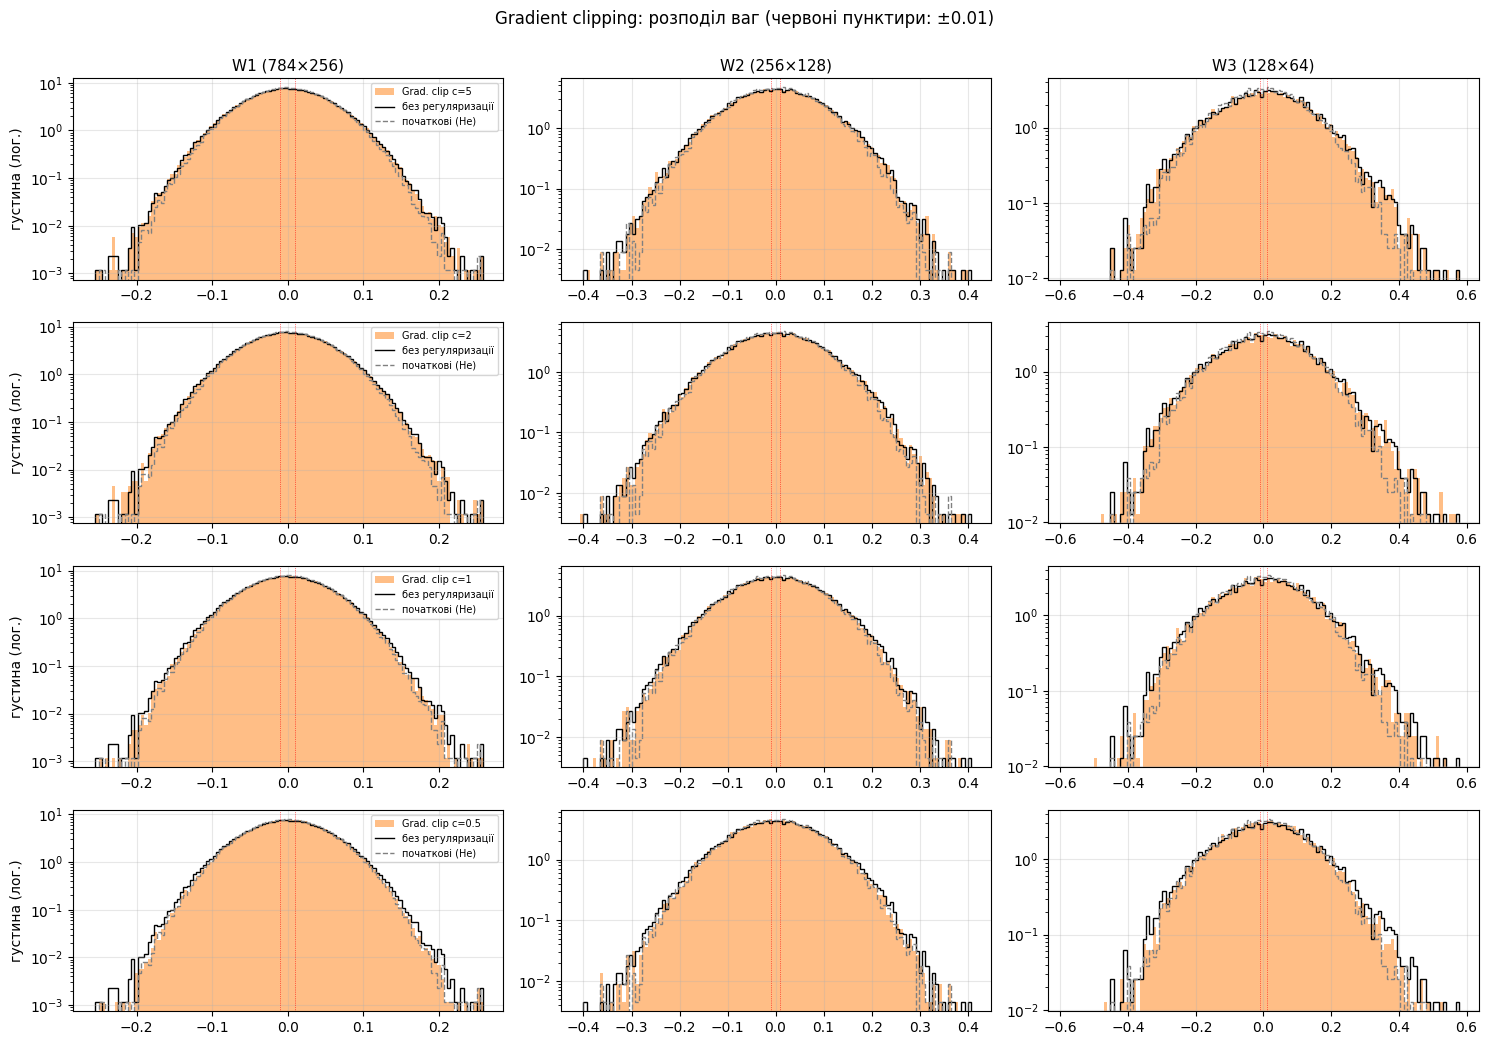

In [25]:
plot_weight_hists(GC_NAMES, 'Gradient clipping: розподіл ваг (червоні пунктири: ±0.01)')

**Gradient clipping.** Усі чотири гістограми практично збігаються з базовою моделлю ($\sigma(W^{(1)})$ 0,0512–0,0531, $\sigma(W^{(3)})$ 0,1288–0,1367). Лише при найсильнішому clipping ($c = 0{,}5$) розподіл $W^{(3)}$ трохи вужчий (0,1288 проти 0,1365), що узгоджується з повільнішим навчанням. Отже, gradient clipping не формує ні пік у нулі, ні межі на розподілі.

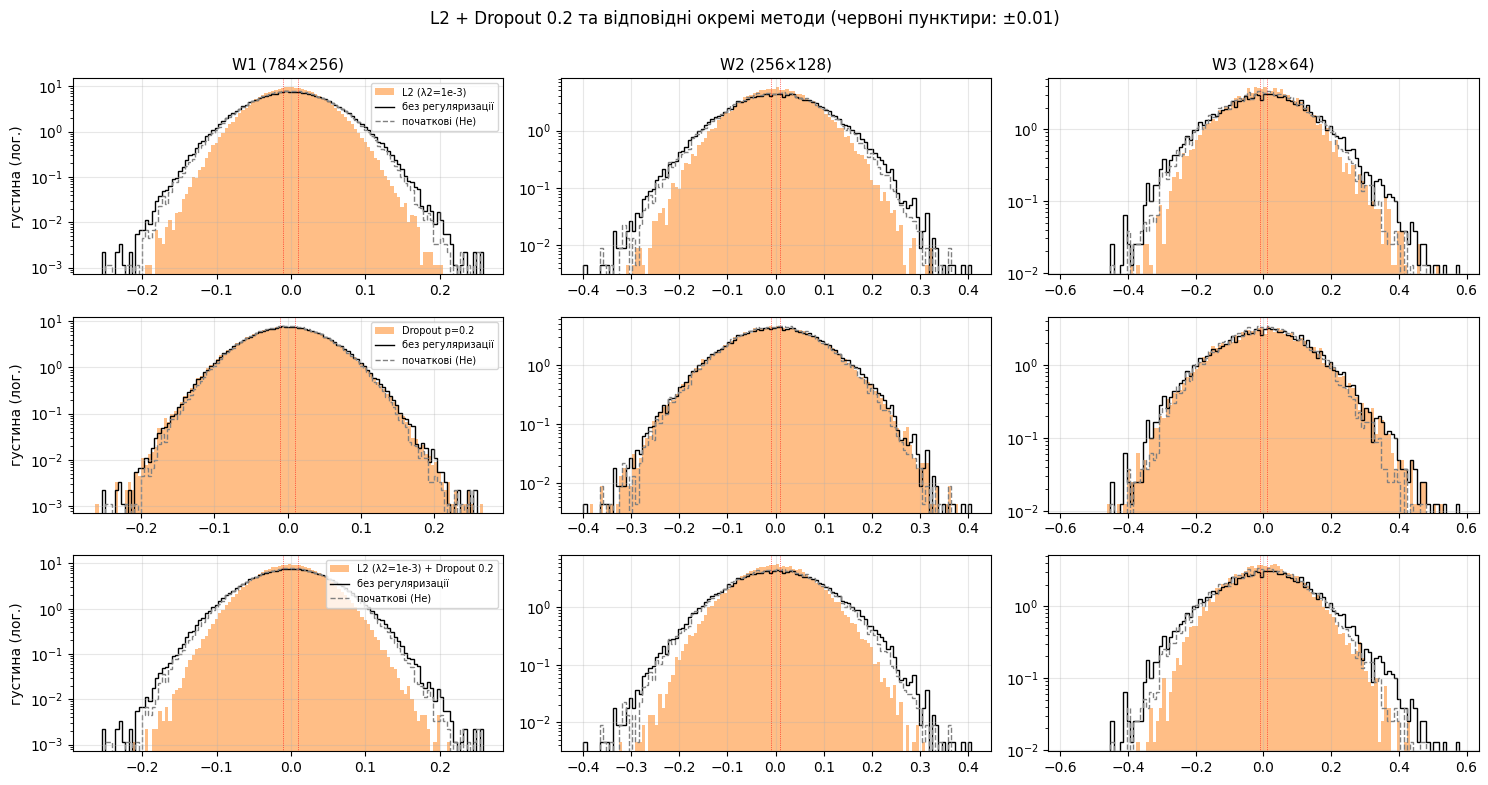

In [26]:
plot_weight_hists([best_l2, 'do_0.2', 'combo'], 'L2 + Dropout 0.2 та відповідні окремі методи (червоні пунктири: ±0.01)')

**L2 + Dropout 0,2.** Розподіл комбінованої моделі майже збігається з розподілом L2 окремо ($\sigma(W^{(1)})$ 0,0423 проти 0,0425; $\sigma(W^{(3)})$ 0,1092 проти 0,1121), а Dropout 0,2 окремо повторює базовий. Форму розподілу ваг визначає L2; Dropout у цьому комбінованому прикладі її не змінює.

### 4.3 Залежність мертвих нейронів від точності

Діаграма розсіювання: вісь $x$ — відсоток мертвих нейронів, вісь $y$ — validation accuracy, кожна точка — окремий експеримент (19 конфігурацій, у тому числі додаткові; підписи у правій колонці з'єднано лініями з точками, щоб вони не перекривалися). Колір — метод регуляризації.

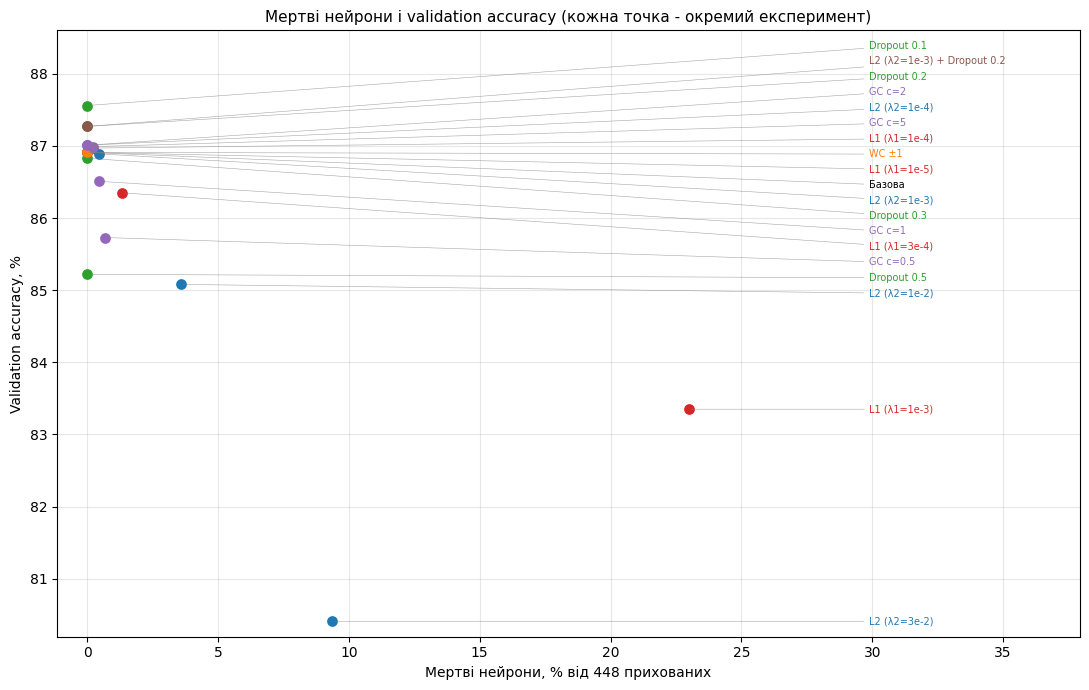

In [27]:
FAMILY_COLOR = {'Без регуляризації': 'k', 'L1': 'C3', 'L2': 'C0', 'Dropout': 'C2', 'Weight clipping': 'C1',
                'Gradient clipping': 'C4', 'L2 + Dropout': 'C5'}
short = {n: RESULTS[n]['label'].replace('Без регуляризації', 'Базова').replace('Weight clip ', 'WC ').replace('Grad. clip ', 'GC ')
         .replace('Dropout p=', 'Dropout ') for n in ORDER}


def labeled_scatter(xs, ys, title, xlabel, ylabel):
    """Діаграма розсіювання з підписами у правій колонці (щоб підписи не перекривалися)."""
    fig, ax = plt.subplots(figsize=(11, 7))
    for n, x, y in zip(ORDER, xs, ys):
        ax.scatter(x, y, color=FAMILY_COLOR[RESULTS[n]['family']], s=45, zorder=3)
    x_lo, x_hi = min(xs), max(xs)
    span = (x_hi - x_lo) or 1.0
    x_lab = x_hi + 0.30 * span
    order = np.argsort(ys, kind='stable')
    gap = 0.03 * (max(ys) - min(ys))                     # мінімальна вертикальна відстань між підписами
    k = np.arange(len(order))
    y_sorted = np.array(ys)[order]
    y_slots = IsotonicRegression().fit_transform(k, y_sorted - k * gap) + k * gap     # підписи поряд із точками без перекриття
    for slot, i in zip(y_slots, order):
        ax.annotate(short[ORDER[i]], xy=(xs[i], ys[i]), xytext=(x_lab, slot), fontsize=7, va='center',
                    color=FAMILY_COLOR[RESULTS[ORDER[i]]['family']],
                    arrowprops=dict(arrowstyle='-', lw=0.4, color='gray', alpha=0.7))
    ax.set_xlim(x_lo - 0.05 * span, x_lab + 0.35 * span)
    pad = 0.03 * (max(ys) - min(ys))
    ax.set_ylim(min(min(ys), y_slots.min()) - pad, max(max(ys), y_slots.max()) + pad)    # підписи не виходять за осі
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.tight_layout()
    plt.show()


dead_x = [RESULTS[n]['dead_pct'] for n in ORDER]
acc_y = [100 * RESULTS[n]['val_acc'] for n in ORDER]
labeled_scatter(dead_x, acc_y, 'Мертві нейрони і validation accuracy (кожна точка - окремий експеримент)',
                'Мертві нейрони, % від 448 прихованих', 'Validation accuracy, %')

Основна маса точок (11 конфігурацій) лежить на $x = 0$ або дуже близько до нього, і їхня validation accuracy розкидана від 85,2 % (Dropout 0,5) до 87,6 % (Dropout 0,1). Ще сім моделей мають від 0,22 до 1,34 % мертвих нейронів (1–6 нейронів). Далі праворуч розташовані сильно регуляризовані моделі: L2 $10^{-2}$ (3,57 %; 85,08 %), L2 $3\cdot10^{-2}$ (9,38 %; 80,41 %), L1 $10^{-3}$ (22,99 %; 83,35 %).

**1. Чи існує залежність між кількістю мертвих нейронів і якістю класифікації?** Сильно регуляризовані моделі мають більше мертвих нейронів і нижчу точність. Однак цей результат не доводить причинного зв’язку.

**2. Чи призводить велика кількість мертвих нейронів до зниження точності?** Ні. L1 10⁻³ має 103 мертві нейрони й accuracy 83,35%, тоді як L2 0,03 — 42 нейрони та нижчу accuracy 80,41%.

**3. Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** Так. Dropout 0.1 і 0.5 не мають мертвих нейронів, але дають accuracy 87,56% і 85,22% відповідно.

**4. Чи є оптимальний баланс між sparsity ваг і кількістю мертвих нейронів?** L1 10⁻⁴ є вдалим компромісом серед досліджених конфігурацій: sparsity 43,02%, один мертвий нейрон, accuracy 86,97% і loss 0,3840. Це не доводить існування універсального оптимуму; результат залежить від конфігурації та порога sparsity.

### 4.4 Дослідження залежності регуляризації від якості

**Дослідницьке питання:** чи завжди збільшення сили регуляризації покращує узагальнювальну здатність нейронної мережі?

Збільшення сили регуляризації не завжди покращує узагальнення. Помірні L1 = 10⁻⁴ та L2 = 10⁻³ зменшують validation loss із 0,4141 до 0,3840 та 0,3863 відповідно, майже не змінюючи accuracy. При L2 = 0,03 навчальна accuracy падає до 81,34%, валідаційна — до 80,41%. Це ознака недонавчання: малий розрив між вибірками сам по собі не означає якісної моделі.

Мала величина ваг характеризує їхній масштаб. Нульова вага дорівнює нулю точно; майже нульова в цій роботі задовольняє |W| < 0,01. Неактивний нейрон має нульовий вихід ReLU на конкретному вході. Мертвий нейрон не активується на жодному об’єкті досліджуваної вибірки. Випадкове вимкнення Dropout не означає, що нейрон мертвий. Надмірно регуляризована модель недостатньо добре засвоює навіть навчальні дані через надто сильні обмеження.

## Висновок

Реалізовано MLP 784–256–128–64–10 на NumPy з власними прямим проходом, backpropagation і SGD. Чисельна перевірка базової мережі дала максимальну відносну похибку приблизно 1,1·10⁻⁷. Після збереження та відновлення ймовірності й передбачені класи збігаються.

Базова validation accuracy становить 86,91%. Найвищу accuracy серед досліджених конфігурацій отримано з Dropout 0.1 — 87,56%, найменший validation loss — із L1 10⁻⁴: 0,3840. Помірна регуляризація покращує окремі показники, а надмірна спричиняє недонавчання. L1 збільшує частку майже нульових ваг; L2 зменшує їхній масштаб.

Weight clipping ±1 не дав помітних відмінностей від baseline. Сильний gradient clipping згладжує коливання loss, але сповільнює навчання. Комбінація L2 + Dropout 0.2 покращила loss порівняно з відповідними окремими методами, проте не підвищила accuracy понад окремий Dropout. Кількість мертвих нейронів сама по собі не визначає якість моделі. Висновки обмежені обраною підвибіркою та одним запуском кожної конфігурації.